# Business Performance and Customer Experience Analysis

Background

We have established the analysis structure in the previous notebooks by validating the order lifecycle, resolving customer and seller locations against official geographic references, and defining conservative rules for linking reviews to the entities they evaluate. The review text was then decomposed into specific evaluative aspects and aggregated into separate Product, Seller, and Delivery ratings. These constructed ratings distinguish different parts of the purchasing experience and complement the original overall customer rating.

Building on these outputs, this notebook examines marketplace performance and customer experience within a common analytical framework. It first analyzes Business Performance across Customer, Product / Category, Seller, and Delivery, then evaluates Customer Experience using the constructed ratings and the original customer rating, and finally compares commercial scale with Product and Seller experience.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import (
    FuncFormatter,
    LogLocator,
    NullFormatter,
    PercentFormatter,
)
import numpy as np
import pandas as pd
import seaborn as sns

pd.options.display.float_format = '{:,.2f}'.format

sns.set_theme(
    style='whitegrid',
    context='notebook',
    palette='deep',
)

PALETTE = sns.color_palette('colorblind')
UNCATEGORIZED = 'Uncategorized'


In [2]:
PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(exist_ok=True)


def save_figure(fig, name):
    fig.savefig(
        FIGURE_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURE_DIR / f"{name}.svg",
        bbox_inches="tight",
    )

orders = pd.read_csv(
    RAW_DIR / 'olist_orders_dataset.csv',
    usecols=[
        'order_id',
        'customer_id',
        'order_status',
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
    ],
    parse_dates=[
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
    ],
)

review_df = pd.read_csv(
    PROCESSED_DIR / 'reviews_translated.csv',
    usecols=[
        'review_id',
        'order_id',
        'review_score',
        'review_comment_message',
        'review_answer_timestamp',
    ],
    parse_dates=['review_answer_timestamp'],
)

items = pd.read_csv(
    RAW_DIR / 'olist_order_items_dataset.csv',
    usecols=[
        'order_id',
        'order_item_id',
        'product_id',
        'seller_id',
        'price',
    ],
)

products = pd.read_parquet(
    PROCESSED_DIR / 'products.parquet',
)

customer_locations = pd.read_parquet(
    PROCESSED_DIR / 'customers_geo_processed.parquet'
)[
    ['customer_unique_id', 'state_name', 'geo_status']
]

seller_locations = pd.read_parquet(
    PROCESSED_DIR / 'sellers_geo_processed.parquet'
)[
    ['state_name', 'geo_status']
]


## **Business Performance Analysis**

This notebook prepares shared order and item analysis tables, checks their key integrity conditions, and compares all recorded activity with completed (delivered) activity. An order is treated as completed when `order_status` is `delivered`. The Customer, Product / Category, and Seller sections use completed orders to examine purchasing frequency, customer geography, commercial scale, category breadth, and activity over time. Merchandise value is the sum of item prices across completed orders, excluding freight.

The Delivery section starts from completed orders with saved delivery attribution, then applies date and coordinate eligibility conditions for the relevant comparisons.


### 0. Integrity Check and Analysis Base

Prepare the shared order-level context. Item measures (values, number of units and sellers) are first aggregated to one row per order so they can be attached without changing the order grain.

In [3]:
assert not items.duplicated(['order_id', 'order_item_id']).any()
assert items.order_id.isin(orders.order_id).all()

order_item_totals = (
    items
    .groupby('order_id')
    .agg(
        ordered_units=('order_item_id', 'size'),
        ordered_merchandise_value=('price', 'sum'),
        n_unique_sellers=('seller_id', 'nunique'),
    )
)

assert orders.customer_id.isin(customer_locations.index).all()

order_context = orders.merge(
    customer_locations[
        ['customer_unique_id', 'state_name']
    ],
    left_on='customer_id',
    right_index=True,
    how='left',
    validate='1:1',
).merge(
    order_item_totals,
    left_on='order_id',
    right_index=True,
    how='left',
    validate='1:1',
)


order_context['item_data_available'] = order_context.ordered_units.notna()
order_context['completed'] = order_context.order_status.eq('delivered')

assert order_context.order_purchase_timestamp.notna().all()

order_context['purchase_month'] = (
    order_context.order_purchase_timestamp.dt.to_period('M')
)

Prepare the item-level business table by attaching translated product category and order context. Missing category labels are retained as `Uncategorized` so category summaries preserve the completed-commerce totals.


In [4]:
assert items.product_id.isin(products.index).all()
assert items.seller_id.isin(seller_locations.index).all()
assert items[
    ['price', 'order_id', 'product_id', 'seller_id']
].notna().all().all()
assert items.price.ge(0).all()
assert not products.product_category_name.eq(UNCATEGORIZED).any()

item_business_base = items.merge(
    products,
    left_on='product_id',
    right_index=True,
    how='left',
    validate='m:1',
)

item_business_base = item_business_base.rename(
    columns={'product_category_name': 'category'}
)

item_business_base['category'] = (
    item_business_base.category.fillna(UNCATEGORIZED)
)

item_business_base = item_business_base.merge(
    order_context[
        [
            'order_id',
            'customer_unique_id',
            'purchase_month',
            'completed',
        ]
    ],
    on='order_id',
    how='left',
    validate='m:1',
)

All orders recorded as delivered have item records, so completed commercial measures can be constructed without replacing missing item values with zero. Create the completed-order tables that will be used throughout the remaining analysis.


In [5]:
assert order_context.loc[
    order_context.completed,
    'item_data_available',
].all()

completed_order_context = (
    order_context
    .loc[order_context.completed]
    .copy()
)

completed_item_business = (
    item_business_base
    .loc[item_business_base.completed]
    .copy()
)

Compare total recorded activity with completed activity to confirm that restricting the business-performance analysis to completed orders retains nearly all observed commerce.

In [6]:
overall_comparison = pd.DataFrame(
    {
        'observed': [
            len(order_context),
            item_business_base.order_id.nunique(),
            len(item_business_base),
            item_business_base.price.sum(),
        ],
        'completed': [
            len(completed_order_context),
            completed_item_business.order_id.nunique(),
            len(completed_item_business),
            completed_item_business.price.sum(),
        ],
    },
    index=[
        'orders',
        'item_linked_orders',
        'units',
        'merchandise_value',
    ],
)

assert overall_comparison.completed.le(
    overall_comparison.observed
).all()

overall_comparison['completed_share_pct'] = (
    overall_comparison.completed
    / overall_comparison.observed
    * 100
)

display(overall_comparison)


,observed,completed,completed_share_pct
orders,"99,441.00","96,478.00",97.02
item_linked_orders,"98,666.00","96,478.00",97.78
units,"112,650.00","110,197.00",97.82
merchandise_value,"13,591,643.70","13,221,498.11",97.28


Define a reusable aggregation helper for the product, category, seller, and temporal sections. Within each requested group, it counts item rows as units, counts distinct orders, and sums item prices as merchandise value. These sections pass completed-order items to the helper. An order containing multiple products, categories, or sellers can be counted in more than one group, so group-level order counts are not necessarily additive.


In [7]:
def summarize_commerce(frame, keys):
    """Aggregate item-level commerce measures at the requested grain.

    Parameters
    ----------
    frame : pandas.DataFrame
        Item-level commerce data containing `order_item_id`, `order_id`,
        `price`, and the requested grouping columns.
        After the initial coverage comparison, this notebook passes completed
        (`delivered`) order items to the function.
    keys : list[str]
        Columns defining the output grain.

    Returns
    -------
    pandas.DataFrame
        One row per observed group with unit count, distinct order count,
        and merchandise value. Merchandise value is the sum of item price
        and excludes freight.
    """
    summary = (
        frame
        .groupby(
            keys,
            observed=True,
            dropna=False,
        )
        .agg(
            units=('order_item_id', 'size'),
            orders=('order_id', 'nunique'),
            merchandise_value=('price', 'sum'),
        )
    )

    summary[
        ['units', 'orders']
    ] = summary[
        ['units', 'orders']
    ].astype('int64')

    assert summary.index.is_unique

    return summary


**Observation**

Completed orders account for approximately 97.8% of recorded item units and 97.3% of recorded merchandise value. The subsequent commercial analysis uses completed orders and therefore describes the completed activity represented in the dataset. Delivery comparisons apply additional attribution and data-availability conditions within this population.


### 1. Customer

**Examine repeated purchasing and the geographic distribution of customer activity across states.**



#### Inspect Repeated Purchasing

Count the number of distinct completed orders associated with each `customer_unique_id` to examine the extent of repeated purchasing observed in the dataset.

In [8]:
customer_order_counts = (
    completed_order_context
    .groupby('customer_unique_id')
    .order_id.nunique()
    .rename('n_completed_orders')
)

customer_order_distribution = (
    customer_order_counts
    .value_counts()
    .sort_index()
    .to_frame('customers')
)

customer_order_distribution.index.name = 'n_completed_orders'

customer_order_distribution['customer_share_pct'] = (
    customer_order_distribution.customers
    / len(customer_order_counts)
    * 100
)

repeat_count = customer_order_counts.gt(1).sum()

display(customer_order_distribution.round(3))

print(
    f'{repeat_count:,} / {len(customer_order_counts):,} customers '
    f'({repeat_count / len(customer_order_counts):.2%}) have more than one '
    f'completed order.'
)


,customers,customer_share_pct
n_completed_orders,,
1,90557,97.00
2,2573,2.76
3,181,0.19
4,28,0.03
5,9,0.01
6,5,0.01
7,3,0.00
9,1,0.00
15,1,0.00


2,801 / 93,358 customers (3.00%) have more than one completed order.


**Observation**


The examination of this dataset shows relatively few repeat purchases. As a result, the available data provide too few evaluations for analyzing long-term customer characteristics or repeat-purchasing behavior in a meaningful way. Therefore, the analysis proceeds to other dimensions of customer behavior.


#### Analyze Customer Geography

Aggregate completed customer activity by state using distinct customers, completed orders, and merchandise value. Customer counts are calculated independently within each state. Order and merchandise-value shares use the corresponding totals across the state groups as their denominators; rows without a state name are omitted by the grouping.


In [9]:
customer_state_summary = (
    completed_order_context
    .groupby('state_name')
    .agg(
        customers=('customer_unique_id', 'nunique'),
        orders=('order_id', 'size'),
        merchandise_value=('ordered_merchandise_value', 'sum'),
    )
)

customer_state_summary['order_share'] = (
    customer_state_summary.orders
    / customer_state_summary.orders.sum()
)

customer_state_summary['value_share'] = (
    customer_state_summary.merchandise_value
    / customer_state_summary.merchandise_value.sum()
)

top_customer_states = customer_state_summary.nlargest(10, 'orders')

display(
    top_customer_states
    .assign(
        order_share_pct=lambda d: d.order_share * 100,
        value_share_pct=lambda d: d.value_share * 100,
    )
    .loc[
        :,
        [
            'customers',
            'orders',
            'merchandise_value',
            'order_share_pct',
            'value_share_pct',
        ],
    ]
    .round(2)
)

,customers,orders,merchandise_value,order_share_pct,value_share_pct
state_name,,,,,
São Paulo,39156,40501,"5,067,633.16",41.98,38.33
Rio de Janeiro,11917,12350,"1,759,651.13",12.80,13.31
Minas Gerais,11001,11354,"1,552,481.83",11.77,11.74
Rio Grande do Sul,5168,5345,"728,897.47",5.54,5.51
Paraná,4769,4923,"666,063.51",5.10,5.04
Santa Catarina,3449,3546,"507,012.13",3.68,3.83
Bahia,3158,3256,"493,584.14",3.37,3.73
Distrito Federal,2019,2080,"296,498.41",2.16,2.24
Espírito Santo,1928,1995,"268,643.45",2.07,2.03


Compare order share with merchandise-value share for the leading customer states.

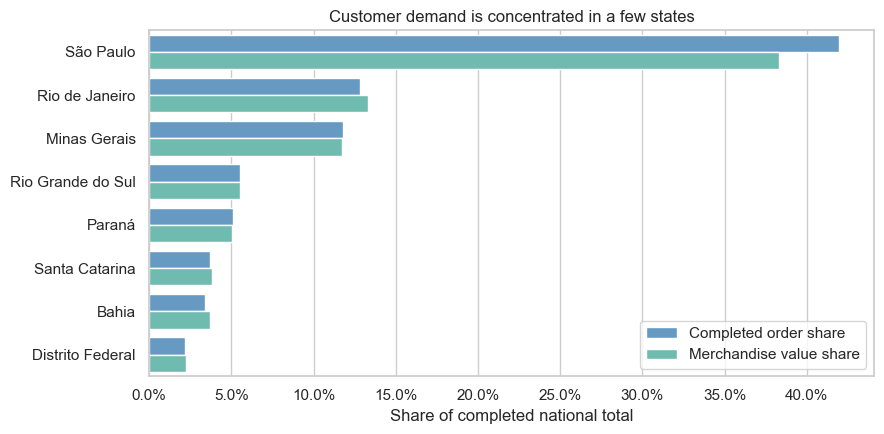

In [10]:
plot_customer_states = (
    top_customer_states
    .head(8)
    .reset_index()
    .melt(
        id_vars='state_name',
        value_vars=['order_share', 'value_share'],
        var_name='metric',
        value_name='share',
    )
)

plot_customer_states['metric'] = plot_customer_states.metric.map(
    {
        'order_share': 'Completed order share',
        'value_share': 'Merchandise value share',
    }
)

state_order = top_customer_states.head(8).index

fig, ax = plt.subplots(figsize=(9, 4.5))

sns.barplot(
    data=plot_customer_states,
    y='state_name',
    x='share',
    hue='metric',
    order=state_order,
    palette=["#579BD3", "#64C7B8"],
    ax=ax,
)

ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(
    xlabel='Share of completed national total',
    ylabel='',
    title='Customer demand is concentrated in a few states',
)
ax.legend(title='')

fig.tight_layout()
plt.show()

save_figure(fig, 'customer_demand_by_state')

**Observation**

In the state summary, São Paulo accounts for about 42% of completed orders and 38% of completed merchandise value. Rio de Janeiro and Minas Gerais contribute another 13% and 12% of completed orders, respectively. Together, these three states account for roughly two thirds of the completed orders represented in the state summary.

The differences between order share and merchandise-value share indicate that geographic concentration in order volume does not exactly correspond to concentration in merchandise value.


### 2. Product / Category

**Compare completed product and category performance, then examine how completed marketplace activity and category mix change over time.**

#### Compare Product and Category Performance

Summarize overall completed commerce, then compare category performance and examine the leading products by units and merchandise value.

Inspect the overall scale of completed commerce in terms of units, orders, and merchandise value.

In [11]:
market_totals = summarize_commerce(
    completed_item_business.assign(
        market='Completed orders'
    ),
    ['market'],
)

display(
    market_totals.T.rename(
        columns={'Completed orders': 'value'}
    )
)


market,value
units,"110,197.00"
orders,"96,478.00"
merchandise_value,"13,221,498.11"


Aggregate completed item rows by category, calculating units, distinct orders, merchandise value, and their ranks. Display the categories appearing in the top ten by units or merchandise value, together with their order counts, unit ranks, and merchandise-value ranks.


In [12]:
category_performance = summarize_commerce(
    completed_item_business,
    ['category'],
)

category_rankings = category_performance.copy()

for metric in [
    'units',
    'orders',
    'merchandise_value',
]:
    category_rankings[metric + '_rank'] = (
        category_rankings[metric]
        .rank(
            method='min',
            ascending=False,
        )
        .astype(int)
    )

show_categories = (
    category_rankings
    .nlargest(10, 'units')
    .index
    .union(
        category_rankings
        .nlargest(
            10,
            'merchandise_value',
        )
        .index,
        sort=False,
    )
)

display(
    category_rankings
    .loc[show_categories]
    .sort_values('units_rank')
    [
        [
            'orders',
            'units',
            'merchandise_value',
            'units_rank',
            'merchandise_value_rank',
        ]
    ]
)

uncategorized_units = category_performance.loc[
    UNCATEGORIZED,
    'units',
]

print(
    f'Uncategorized: {uncategorized_units:,} completed item rows '
    f'({uncategorized_units / len(completed_item_business):.2%}).'
)


,orders,units,merchandise_value,units_rank,merchandise_value_rank
category,,,,,
bed_bath_table,9272,10953,"1,023,434.76",1,3
health_beauty,8647,9465,"1,233,131.72",2,1
sports_leisure,7530,8431,"954,852.55",3,4
furniture_decor,6307,8160,"711,927.69",4,6
computers_accessories,6530,7644,"888,724.61",5,5
housewares,5743,6795,"615,628.69",6,7
watches_gifts,5495,5859,"1,166,176.98",7,2
telephony,4093,4430,"309,860.23",8,14
garden_tools,3448,4268,"470,495.28",9,11


Uncategorized: 1,559 completed item rows (1.41%).


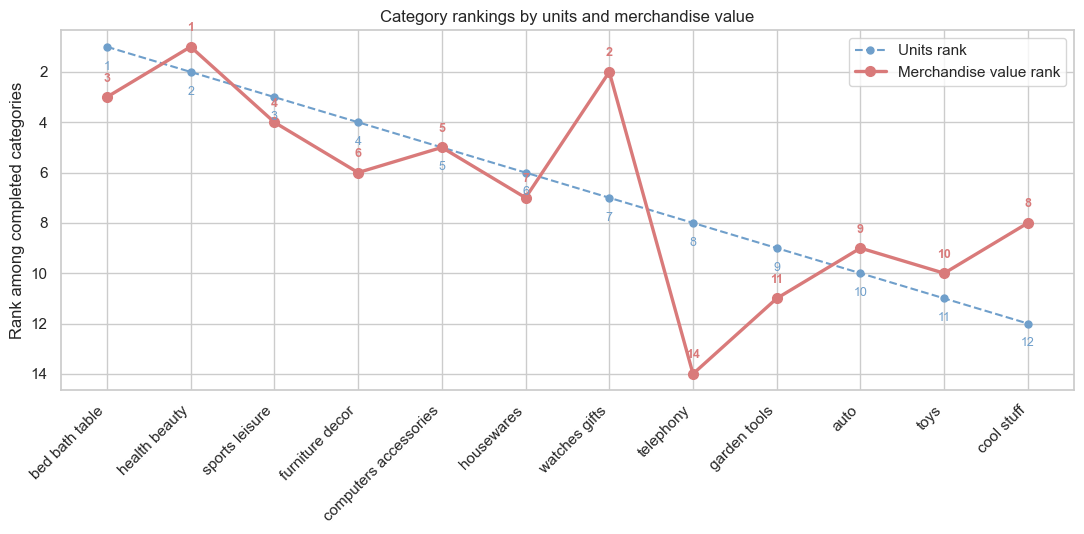

In [13]:
UNIT_COLOR = '#6F9FCB'
VALUE_COLOR = '#D97A7A'

category_rank_plot = (
    category_rankings
    .loc[show_categories]
    .sort_values('units_rank')
    .copy()
)

category_rank_plot['category_label'] = (
    category_rank_plot.index
    .str.replace('_', ' ', regex=False)
)

x = np.arange(len(category_rank_plot))

fig, ax = plt.subplots(figsize=(11, 5.5))

# Units: secondary/reference series
ax.plot(
    x,
    category_rank_plot['units_rank'],
    marker='o',
    linestyle='--',
    linewidth=1.5,
    markersize=5,
    color=UNIT_COLOR,
    label='Units rank',
    zorder=2,
)

# Merchandise value: primary series
ax.plot(
    x,
    category_rank_plot['merchandise_value_rank'],
    marker='o',
    linestyle='-',
    linewidth=2.4,
    markersize=7,
    color=VALUE_COLOR,
    label='Merchandise value rank',
    zorder=3,
)

# Exact ranks
for i, row in enumerate(category_rank_plot.itertuples()):
    ax.annotate(
        f'{int(row.units_rank)}',
        (i, row.units_rank),
        xytext=(0, -10),
        textcoords='offset points',
        ha='center',
        va='top',
        fontsize=9,
        color=UNIT_COLOR,
    )

    ax.annotate(
        f'{int(row.merchandise_value_rank)}',
        (i, row.merchandise_value_rank),
        xytext=(0, 9),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=9,
        color=VALUE_COLOR,
        fontweight='bold',
    )

ax.set_xticks(
    x,
    category_rank_plot['category_label'],
    rotation=45,
    ha='right',
)

ax.set(
    xlabel='',
    ylabel='Rank among completed categories',
    title='Category rankings by units and merchandise value',
)

ax.invert_yaxis()
ax.legend()

fig.tight_layout()
plt.show()

save_figure(fig, 'category_volume_vs_value')

Aggregate completed item rows at the product level and inspect a compact set of leading products identified by units and merchandise value.

In [14]:
product_performance = summarize_commerce(
    completed_item_business,
    ['product_id'],
)

product_performance = (
    product_performance
    .join(
        products
        .rename(
            columns={'product_category_name': 'category'}
        )
        .fillna(UNCATEGORIZED),
        validate='1:1',
    )
)


product_rankings = product_performance.assign(
    units_rank=(
        product_performance.units
        .rank(
            method='min',
            ascending=False,
        )
        .astype(int)
    ),
    value_rank=(
        product_performance.merchandise_value
        .rank(
            method='min',
            ascending=False,
        )
        .astype(int)
    ),
)

top_products = (
    product_rankings
    .nsmallest(3, 'units_rank')
    .index
    .union(
        product_rankings
        .nsmallest(3, 'value_rank')
        .index,
        sort=False,
    )
)

display(
    product_rankings.loc[
        top_products,
        [
            'category',
            'orders',
            'units',
            'merchandise_value',
            'units_rank',
            'value_rank',
        ],
    ]
)


,category,orders,units,merchandise_value,units_rank,value_rank
product_id,,,,,,
aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,425,520,"37,104.30",1,10
422879e10f46682990de24d770e7f83d,garden_tools,352,484,"26,577.22",2,17
99a4788cb24856965c36a24e339b6058,bed_bath_table,456,477,"42,049.66",3,5
bb50f2e236e5eea0100680137654686c,health_beauty,186,194,"63,560.00",14,1
6cdd53843498f92890544667809f1595,health_beauty,148,153,"53,652.30",23,2
d6160fb7873f184099d9bc95e30376af,computers,33,33,"45,949.35",315,3


**Observation**

The completed-order tables show that product and category performance differs depending on whether it is measured by item units or merchandise value. Comparing unit and value rankings is therefore useful because the categories or products with the most units do not necessarily generate the highest merchandise value. `Uncategorized` is retained so that missing category labels do not remove completed commerce from the totals.


#### Analyze Monthly Marketplace Activity

Group completed orders by their purchase month. First, inspect the purchase-date coverage of these orders and define a central observation window that excludes the sparse edges of the series. Then, examine merchandise value and merchandise value per unit over this window, followed by a matching-month comparison of merchandise value in 2017 and 2018.


Determine the available purchase-month range and, within each month, count the calendar dates on which at least one order recorded as completed was purchased. Construct the monthly summary of completed units, distinct orders, and merchandise value.


In [15]:
month_coverage = (
    completed_order_context
    .groupby('purchase_month')
    .agg(
        completed_orders=('order_id', 'size'),
        first_purchase=('order_purchase_timestamp', 'min'),
        last_purchase=('order_purchase_timestamp', 'max'),
        days_with_purchases=(
            'order_purchase_timestamp',
            lambda s: s.dt.normalize().nunique(),
        ),
    )
)

month_range = pd.period_range(
    completed_order_context.purchase_month.min(),
    completed_order_context.purchase_month.max(),
    freq='M',
)

month_coverage = (
    month_coverage
    .reindex(month_range)
    .rename_axis('purchase_month')
)

month_coverage[
    ['completed_orders', 'days_with_purchases']
] = (
    month_coverage[
        ['completed_orders', 'days_with_purchases']
    ]
    .fillna(0)
    .astype(int)
)

month_coverage['calendar_days'] = (
    month_coverage.index.days_in_month
)

month_coverage['daily_coverage_share'] = (
    month_coverage.days_with_purchases
    / month_coverage.calendar_days
)

market_month_summary = summarize_commerce(
    completed_item_business,
    ['purchase_month'],
)

market_month_summary = (
    market_month_summary
    .reindex(month_range)
    .rename_axis('purchase_month')
)

display(
    month_coverage
    .assign(
        first_purchase=lambda d: d.first_purchase.dt.date,
        last_purchase=lambda d: d.last_purchase.dt.date,
    )
    .drop(columns='daily_coverage_share')
)


,completed_orders,first_purchase,last_purchase,days_with_purchases,calendar_days
purchase_month,,,,,
2016-09,1,2016-09-15,2016-09-15,1,30
2016-10,265,2016-10-03,2016-10-10,8,31
2016-11,0,NaT,NaT,0,30
2016-12,1,2016-12-23,2016-12-23,1,31
2017-01,750,2017-01-05,2017-01-31,27,31
2017-02,1653,2017-02-01,2017-02-28,28,28
2017-03,2546,2017-03-01,2017-03-31,31,31
2017-04,2303,2017-04-01,2017-04-30,30,30
2017-05,3546,2017-05-01,2017-05-31,31,31


Inspect completed activity at the end of August 2018 before defining the main comparison window.

In [16]:
august_tail = (
    completed_order_context
    .loc[
        completed_order_context.order_purchase_timestamp.ge(
            '2018-08-25'
        )
        & completed_order_context.order_purchase_timestamp.lt(
            '2018-09-01'
        )
    ]
    .groupby(
        completed_order_context.order_purchase_timestamp.dt.date
    )
    .agg(
        completed_orders=('order_id', 'size'),
    )
)

display(august_tail)


,completed_orders
order_purchase_timestamp,
2018-08-25,69
2018-08-26,73
2018-08-27,66
2018-08-28,39
2018-08-29,11


The purchase-date series for completed orders is sparse before February 2017 and tapers sharply near the end of August 2018. Therefore, **February 2017–July 2018** is used as the central observation window, where completed purchasing is observed throughout each month. Matching-month comparisons use **February–July in 2017 and 2018**.


In [17]:
TREND_START, TREND_END = (
    pd.Period('2017-02', 'M'),
    pd.Period('2018-07', 'M'),
)

trend_months = pd.period_range(
    TREND_START,
    TREND_END,
    freq='M',
)

market_trend = (
    market_month_summary
    .loc[trend_months]
    .rename_axis('purchase_month')
)

display(market_trend)

,units,orders,merchandise_value
purchase_month,,,
2017-02,"1,858.00","1,653.00","234,223.40"
2017-03,"2,897.00","2,546.00","359,198.85"
2017-04,"2,569.00","2,303.00","340,669.68"
2017-05,"4,004.00","3,546.00","489,338.25"
2017-06,"3,489.00","3,135.00","421,923.37"
2017-07,"4,416.00","3,872.00","481,604.52"
2017-08,"4,797.00","4,193.00","554,699.70"
2017-09,"4,737.00","4,150.00","607,399.67"
2017-10,"5,214.00","4,478.00","648,247.65"


Rebase merchandise value and merchandise value per unit to the first month of the central window (`February 2017 = 100`) to compare their relative development over time.

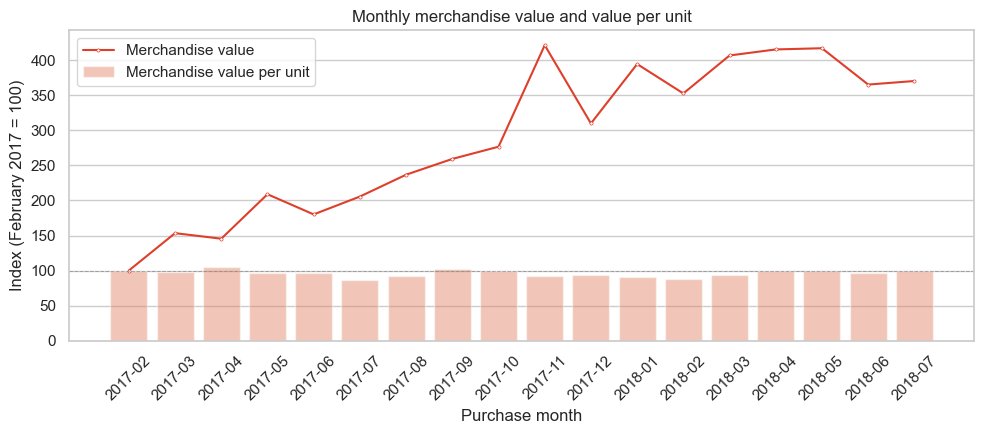

In [18]:
market_trend_plot = (
    market_trend
    .reset_index()
)

market_trend_plot['purchase_month_label'] = (
    market_trend_plot.purchase_month
    .astype(str)
)

market_trend_plot['value_per_unit'] = (
    market_trend_plot.merchandise_value
    / market_trend_plot.units
)

market_trend_plot['merchandise_value_index'] = (
    market_trend_plot.merchandise_value
    / market_trend_plot.merchandise_value.iloc[0]
    * 100
)

market_trend_plot['value_per_unit_index'] = (
    market_trend_plot.value_per_unit
    / market_trend_plot.value_per_unit.iloc[0]
    * 100
)

warm_palette = sns.color_palette('OrRd', 6)

bar_color = warm_palette[3]
line_color = warm_palette[4]

fig, ax = plt.subplots(figsize=(10, 4.5))

sns.barplot(
    data=market_trend_plot,
    x='purchase_month_label',
    y='value_per_unit_index',
    color=bar_color,
    alpha=0.45,
    label='Merchandise value per unit',
    ax=ax,
)

sns.lineplot(
    data=market_trend_plot,
    x='purchase_month_label',
    y='merchandise_value_index',
    color=line_color,
    linewidth=1.5,
    marker='o',
    markersize=2.3,
    markerfacecolor='white',
    markeredgecolor=line_color,
    markeredgewidth=0.5,
    label='Merchandise value',
    ax=ax,
)

ax.axhline(
    100,
    color='gray',
    linestyle='--',
    linewidth=0.7,
    alpha=0.6,
)

ax.set(
    xlabel='Purchase month',
    ylabel='Index (February 2017 = 100)',
    title='Monthly merchandise value and value per unit',
)

ax.tick_params(
    axis='x',
    rotation=45,
)

ax.legend(title='')

fig.tight_layout()
plt.show()

save_figure(fig, 'monthly_merchandise_value_and_value_per_unit')

Compare merchandise value for February–July 2017 with the corresponding calendar months in 2018. The comparison measures year-on-year growth for matching months rather than annualized growth.

In [19]:
yoy_rows = []

for month in range(2, 8):
    earlier = market_month_summary.loc[
        pd.Period(
            year=2017,
            month=month,
            freq='M',
        )
    ]

    later = market_month_summary.loc[
        pd.Period(
            year=2018,
            month=month,
            freq='M',
        )
    ]

    yoy_rows.append(
        {
            'month': pd.Timestamp(
                2018,
                month,
                1,
            ).strftime('%B'),
            'value_2017': earlier.merchandise_value,
            'value_2018': later.merchandise_value,
            'yoy_growth_pct': (
                later.merchandise_value
                / earlier.merchandise_value
                - 1
            ) * 100,
        }
    )

market_yoy = pd.DataFrame(yoy_rows)

display(
    market_yoy.round(1)
)

,month,value_2017,value_2018,yoy_growth_pct
0,February,"234,223.40","826,437.10",252.80
1,March,"359,198.80","953,356.20",165.40
2,April,"340,669.70","973,534.10",185.80
3,May,"489,338.20","977,544.70",99.80
4,June,"421,923.40","856,077.90",102.90
5,July,"481,604.50","867,953.50",80.20


In [20]:
market_yoy_long = (
    market_yoy
    .melt(
        id_vars=[
            'month',
            'yoy_growth_pct',
        ],
        value_vars=[
            'value_2017',
            'value_2018',
        ],
        var_name='year',
        value_name='merchandise_value',
    )
)

market_yoy_long['year'] = (
    market_yoy_long.year.map(
        {
            'value_2017': '2017',
            'value_2018': '2018',
        }
    )
)

market_yoy_long['merchandise_value_million'] = (
    market_yoy_long.merchandise_value
    / 1e6
)

C:\Users\19148\AppData\Local\Temp\ipykernel_38932\1353504359.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


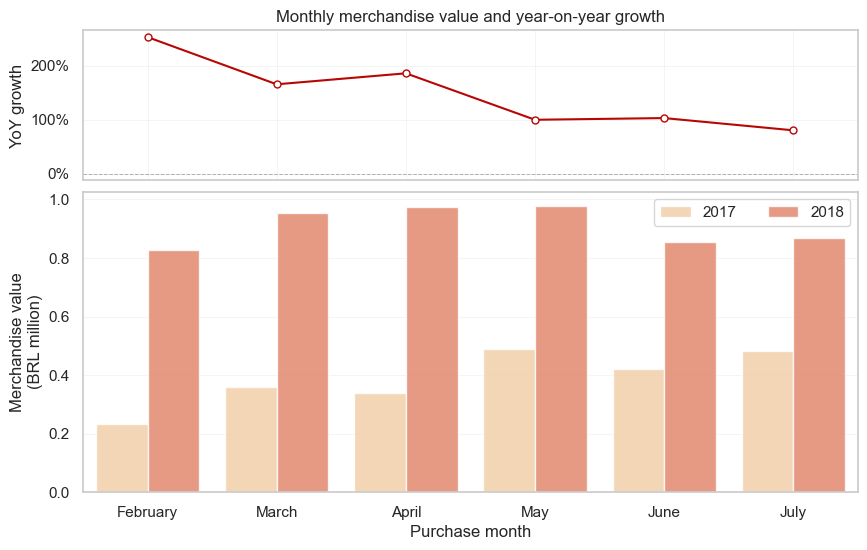

In [21]:
warm_palette = sns.color_palette('OrRd', 6)

bar_colors = [
    warm_palette[1],
    warm_palette[3],
]

line_color = warm_palette[5]

fig, (ax_growth, ax_value) = plt.subplots(
    2,
    1,
    figsize=(10, 6),
    sharex=True,
    gridspec_kw={
        'height_ratios': [1, 2],
        'hspace': 0.05,
    },
)

# Put grid behind all plotted objects.
for ax in (ax_growth, ax_value):
    ax.set_axisbelow(True)
    ax.grid(
        axis='both',
        linewidth=0.5,
        alpha=0.3,
    )


# --- YoY growth ---

sns.lineplot(
    data=market_yoy,
    x='month',
    y='yoy_growth_pct',
    color=line_color,
    linewidth=1.5,
    marker='o',
    markersize=5,
    markerfacecolor='white',
    markeredgecolor=line_color,
    markeredgewidth=1,
    ax=ax_growth,
)

ax_growth.axhline(
    0,
    color='gray',
    linestyle='--',
    linewidth=0.7,
    alpha=0.6,
)

ax_growth.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

ax_growth.set(
    xlabel='',
    ylabel='YoY growth',
    title='Monthly merchandise value and year-on-year growth',
)


# --- Merchandise value ---

sns.barplot(
    data=market_yoy_long,
    x='month',
    y='merchandise_value_million',
    hue='year',
    palette=bar_colors,
    alpha=0.8,
    ax=ax_value,
)

ax_value.set(
    xlabel='Purchase month',
    ylabel='Merchandise value\n(BRL million)',
)

ax_value.legend(
    title='',
    ncol=2,
)

fig.tight_layout()
plt.show()

save_figure(fig, 'monthly_merchandise_value_and_yoy_growth')

**Observation**

Completed merchandise value increases substantially over the central observation window, while merchandise value per item unit remains comparatively stable. Because merchandise value equals units multiplied by value per unit, the larger change in total value primarily reflects growth in completed item units.

For each matching purchase month from February through July, merchandise value is higher in 2018 than in 2017. Summing merchandise value across these six months in each year gives an increase of about 134.4%. These comparisons describe growth within the supplied marketplace extract and do not establish a recurring seasonal pattern.


#### Analyze Category Activity Over Time

Calculate changes in completed units, merchandise value, and merchandise-value share between matching February–July purchase periods in 2017 and 2018. Then examine monthly completed units and merchandise value for the leading categories over the central observation window.


In [22]:
category_month_summary = summarize_commerce(
    completed_item_business,
    ['category', 'purchase_month'],
)

category_month_summary = (
    category_month_summary
    .join(
        market_month_summary[
            [
                'units',
                'merchandise_value',
            ]
        ].rename(
            columns={
                'units': 'market_units',
                'merchandise_value': 'market_value',
            }
        ),
        on='purchase_month',
        validate='m:1',
    )
)

category_month_summary['unit_share'] = (
    category_month_summary.units
    / category_month_summary.market_units
)

category_month_summary['value_share'] = (
    category_month_summary.merchandise_value
    / category_month_summary.market_value.replace(
        0,
        np.nan,
    )
)

category_month_summary = (
    category_month_summary
    .drop(
        columns=[
            'market_units',
            'market_value',
        ]
    )
)

Restrict the category comparison to matching February–July periods in 2017 and 2018.


In [23]:
matched = (
    completed_item_business
    .loc[
        completed_item_business.purchase_month.dt.month.between(
            2,
            7,
        )
        & completed_item_business.purchase_month.dt.year.isin(
            [2017, 2018]
        )
    ]
    .copy()
)

matched['year'] = matched.purchase_month.dt.year

category_period = summarize_commerce(
    matched,
    ['category', 'year'],
)

cat2017 = category_period.xs(
    2017,
    level='year',
)

cat2018 = category_period.xs(
    2018,
    level='year',
)

cat_index = cat2017.index.union(
    cat2018.index
)

cat2017 = cat2017.reindex(
    cat_index,
    fill_value=0,
)

cat2018 = cat2018.reindex(
    cat_index,
    fill_value=0,
)

category_change = pd.DataFrame(
    index=cat_index
)

for metric in [
    'units',
    'merchandise_value',
]:
    category_change[
        metric + '_2017'
    ] = cat2017[metric]

    category_change[
        metric + '_2018'
    ] = cat2018[metric]

    category_change[
        metric + '_change'
    ] = (
        cat2018[metric]
        - cat2017[metric]
    )

category_change[
    'value_share_change_pp'
] = (
    cat2018.merchandise_value
    / cat2018.merchandise_value.sum()
    - cat2017.merchandise_value
    / cat2017.merchandise_value.sum()
) * 100

category_change[
    'share_of_net_value_change_pct'
] = (
    category_change.merchandise_value_change
    / category_change.merchandise_value_change.sum()
    * 100
)

display(
    category_change
    .nlargest(
        8,
        'merchandise_value_change',
    )
    [
        [
            'units_change',
            'merchandise_value_2017',
            'merchandise_value_2018',
            'merchandise_value_change',
            'value_share_change_pp',
            'share_of_net_value_change_pct',
        ]
    ]
)


,units_change,merchandise_value_2017,merchandise_value_2018,merchandise_value_change,value_share_change_pp,share_of_net_value_change_pct
category,,,,,,
watches_gifts,2245,"156,880.39","544,566.90","387,686.51",3.24,12.39
health_beauty,2999,"182,125.03","564,927.89","382,802.86",2.53,12.24
sports_leisure,1832,"166,887.42","380,133.25","213,245.83",-0.20,6.82
bed_bath_table,2313,"194,059.83","396,059.63","201,999.80",-1.08,6.46
computers_accessories,2233,"176,880.66","375,712.79","198,832.13",-0.71,6.36
housewares,1674,"101,279.12","295,613.36","194,334.24",1.07,6.21
furniture_decor,1448,"124,226.06","286,682.21","162,456.15",-0.08,5.19
auto,1361,"101,504.84","262,400.70","160,895.86",0.45,5.14


Plot monthly completed units and merchandise value for the five categories with the highest merchandise value over the central observation window. The same five categories are used in both panels and throughout the period. Each label above a bar shows their combined share of the corresponding monthly marketplace total: units in the upper panel and merchandise value in the lower panel.


In [24]:
central_category = category_month_summary.loc[
    category_month_summary.index.get_level_values(
        'purchase_month'
    ).isin(trend_months)
]

trend_categories = (
    central_category
    .groupby('category')
    .merchandise_value.sum()
    .nlargest(5)
    .index
)

monthly_totals = (
    central_category
    .groupby('purchase_month')
    .agg(
        total_units=('units', 'sum'),
        total_value=('merchandise_value', 'sum'),
    )
    .reindex(trend_months)
)

category_trend_plot = (
    central_category
    .reset_index()
    .loc[
        lambda d: d.category.isin(
            trend_categories
        )
    ]
)

category_trend_plot['merchandise_value_thousand'] = (
    category_trend_plot.merchandise_value
    / 1000
)

category_trend_plot['category_label'] = (
    category_trend_plot.category
    .str.replace(
        '_',
        ' ',
        regex=False,
    )
)

In [25]:
category_order = [
    'watches gifts',
    'computers accessories',
    'sports leisure',
    'bed bath table',
    'health beauty',
]

unit_plot = (
    category_trend_plot
    .pivot(
        index='purchase_month',
        columns='category_label',
        values='units',
    )
    .reindex(
        index=trend_months,
        columns=category_order,
        fill_value=0,
    )
)


value_plot = (
    category_trend_plot
    .pivot(
        index='purchase_month',
        columns='category_label',
        values='merchandise_value_thousand',
    )
    .reindex(
        index=trend_months,
        columns=category_order,
        fill_value=0,
    )
)


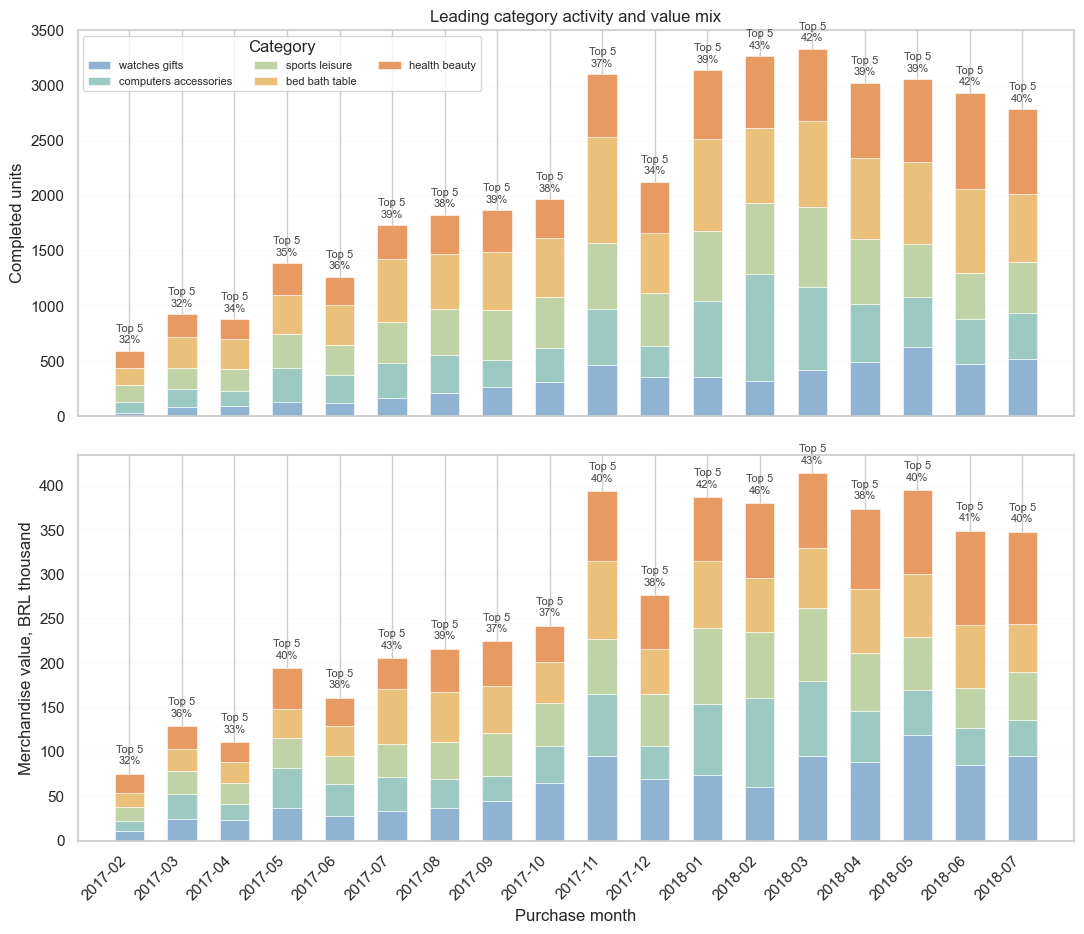

In [26]:
flow_palette = sns.blend_palette(
    [
        '#8FB3D1',  # soft blue
        '#9CC9C2',  # teal
        '#BFD3A6',  # sage
        '#EBC07A',  # sand
        '#E79B63',  # soft orange
    ],
    n_colors=len(category_order),
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 9.5),
    sharex=True,
)

x = np.arange(len(trend_months))
bar_width = 0.56


# total monthly market across all categories
monthly_totals = (
    central_category
    .groupby('purchase_month')
    .agg(
        total_units=('units', 'sum'),
        total_value=('merchandise_value', 'sum'),
    )
    .reindex(trend_months)
)

# plotted totals for the leading categories only
leading_unit_totals = unit_plot.sum(axis=1)

leading_value_totals = (
    value_plot.sum(axis=1)
    * 1000
)

leading_unit_share = (
    leading_unit_totals
    / monthly_totals.total_units
)

leading_value_share = (
    leading_value_totals
    / monthly_totals.total_value
)


# ---------------------------
# Top panel: completed units
# ---------------------------
bottom = np.zeros(len(trend_months))

for category, color in zip(category_order, flow_palette):
    values = unit_plot[category].to_numpy()

    axes[0].bar(
        x,
        values,
        bottom=bottom,
        width=bar_width,
        color=color,
        edgecolor='white',
        linewidth=0.4,
        label=category,
    )

    bottom += values

for i, (total, share) in enumerate(
    zip(leading_unit_totals.to_numpy(), leading_unit_share.to_numpy())
):
    axes[0].text(
        i,
        total + max(leading_unit_totals) * 0.015,
        f'Top 5\n{share:.0%}',
        ha='center',
        va='bottom',
        fontsize=8,
        color='#444444',
    )


# --------------------------------
# Bottom panel: merchandise value
# --------------------------------
bottom = np.zeros(len(trend_months))

for category, color in zip(category_order, flow_palette):
    values = value_plot[category].to_numpy()

    axes[1].bar(
        x,
        values,
        bottom=bottom,
        width=bar_width,
        color=color,
        edgecolor='white',
        linewidth=0.4,
    )

    bottom += values

for i, (total, share) in enumerate(
    zip(value_plot.sum(axis=1).to_numpy(), leading_value_share.to_numpy())
):
    axes[1].text(
        i,
        total + value_plot.sum(axis=1).max() * 0.02,
        f'Top 5\n{share:.0%}',
        ha='center',
        va='bottom',
        fontsize=8,
        color='#444444',
    )


# ---------------------------
# Formatting
# ---------------------------
axes[0].set(
    xlabel='',
    ylabel='Completed units',
    title='Leading category activity and value mix',
)

axes[1].set(
    xlabel='Purchase month',
    ylabel='Merchandise value, BRL thousand',
)

axes[1].set_xticks(
    x,
    [str(month) for month in trend_months],
    rotation=45,
    ha='right',
)

axes[0].legend(
    title='Category',
    ncol=3,
    fontsize=8,
    frameon=True,
    loc='upper left',
)

for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(
        axis='y',
        linewidth=0.35,
        alpha=0.18,
    )
    ax.margins(x=0.04)

fig.tight_layout()
plt.show()

save_figure(fig, 'leading_category_activity_and_value_mix')

**Observation**

Watches/gifts and health/beauty are the largest contributors to the increase in completed merchandise value between the matching February–July periods, adding approximately BRL 388 thousand and BRL 383 thousand, respectively. Together, they account for about one quarter of the net increase in completed merchandise value. 

The monthly category profiles also show that growth in absolute merchandise value does not necessarily imply growth in marketplace share. The stacked bars describes monthly completed unit and merchandise-value levels for the selected five categories. The labels above the bars show their combined share of the monthly marketplace total.


### 3. Seller

**Describe active sellers by completed-order scale and observed category breadth, assess commercial concentration, and compare seller scale across category-breadth groups.**

#### Prepare Active Seller Performance

Aggregate completed item activity to seller grain and attach seller location and category breadth. The analysis is limited to active sellers with at least one completed order.

In [27]:
seller_commerce = summarize_commerce(
    completed_item_business,
    ['seller_id'],
)

known_breadth = (
    completed_item_business
    .loc[
        completed_item_business.category.ne(
            UNCATEGORIZED
        )
    ]
    .groupby('seller_id')
    .category.nunique()
    .rename('category_breadth')
)

# Start from seller_commerce so the population contains
# only sellers with at least one completed order.
seller_performance = (
    seller_commerce
    .join(
        seller_locations[
            ['state_name']
        ],
        how='left',
        validate='1:1',
    )
    .join(
        known_breadth,
        how='left',
        validate='1:1',
    )
)

seller_performance['category_breadth'] = (
    seller_performance.category_breadth
    .fillna(0)
    .astype(int)
)

seller_performance[
    ['units', 'orders']
] = (
    seller_performance[
        ['units', 'orders']
    ]
    .astype(int)
)

assert seller_performance.orders.ge(1).all()

print(
    f'Active sellers: {len(seller_performance):,}'
)

display(
    seller_performance[
        [
            'orders',
            'units',
            'merchandise_value',
            'category_breadth',
        ]
    ].describe()
)

Active sellers: 2,970


,orders,units,merchandise_value,category_breadth
count,"2,970.00","2,970.00","2,970.00","2,970.00"
mean,32.94,37.10,"4,451.68",2.07
std,105.41,119.67,"13,926.97",2.11
min,1.00,1.00,6.50,0.00
25%,2.00,2.00,219.80,1.00
50%,7.00,8.00,846.17,1.00
75%,22.00,26.00,"3,497.88",2.00
max,"1,819.00","1,996.00","226,987.93",27.00


#### Describe Seller Category Breadth

Examine the distribution of active sellers by the number of distinct known categories represented in their completed items. Sellers whose completed items have no known category are shown separately as *Unknown only*.


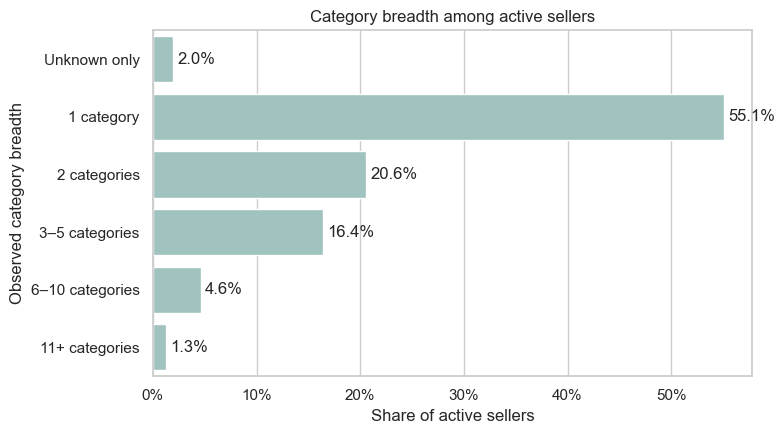

In [28]:
seller_performance['breadth_group'] = pd.cut(
    seller_performance.category_breadth,
    bins=[
        -1,
        0,
        1,
        2,
        5,
        10,
        np.inf,
    ],
    labels=[
        'Unknown only',
        '1 category',
        '2 categories',
        '3–5 categories',
        '6–10 categories',
        '11+ categories',
    ],
)

breadth_distribution = (
    seller_performance.breadth_group
    .value_counts(sort=False)
    .rename('sellers')
    .to_frame()
)

breadth_distribution['share'] = (
    breadth_distribution.sellers
    / breadth_distribution.sellers.sum()
)

breadth_distribution = (
    breadth_distribution
    .reset_index()
    .rename(
        columns={
            'breadth_group': 'categories',
        }
    )
)

fig, ax = plt.subplots(figsize=(8, 4.5))

sns.barplot(
    data=breadth_distribution,
    y='categories',
    x='share',
    color='#9AC9C4',
    orient='h',
    ax=ax,
)

ax.xaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f'{share:.1%}'
        for share in breadth_distribution.share
    ],
    padding=3,
)

ax.set(
    xlabel='Share of active sellers',
    ylabel='Observed category breadth',
    title='Category breadth among active sellers',
)

fig.tight_layout()
plt.show()

#### Describe Seller Order Scale

Group active sellers by their number of completed orders to examine the distribution of seller commercial scale. The resulting shares show how much of the active seller population falls into each completed-order range.

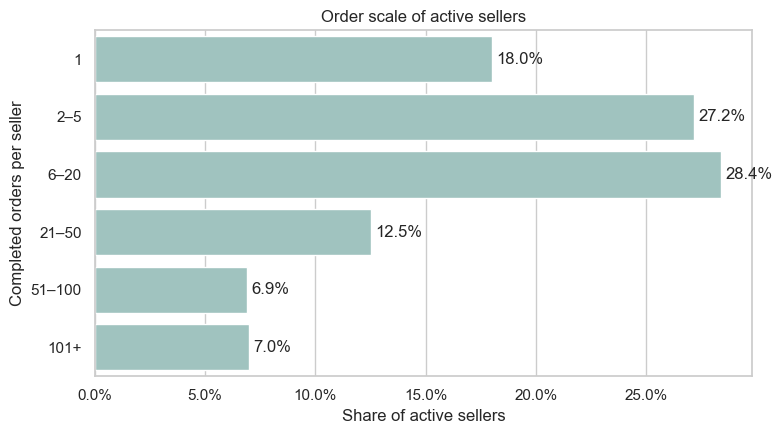

In [29]:
seller_performance['order_scale'] = pd.cut(
    seller_performance.orders,
    bins=[
        0,
        1,
        5,
        20,
        50,
        100,
        np.inf,
    ],
    labels=[
        '1',
        '2–5',
        '6–20',
        '21–50',
        '51–100',
        '101+',
    ],
)
order_distribution = (
    seller_performance.order_scale
    .value_counts(sort=False)
    .rename('sellers')
    .reset_index()
)

order_distribution['share'] = (
    order_distribution.sellers
    / order_distribution.sellers.sum()
)

fig, ax = plt.subplots(figsize=(8, 4.5))

sns.barplot(
    data=order_distribution,
    y='order_scale',
    x='share',
    orient='h',
    color='#9AC9C4',
    ax=ax,
)

ax.xaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f'{share:.1%}'
        for share in order_distribution.share
    ],
    padding=3,
)

ax.set(
    xlabel='Share of active sellers',
    ylabel='Completed orders per seller',
    title='Order scale of active sellers',
)

fig.tight_layout()
plt.show()


#### Assess Seller Commercial Concentration

Rank active sellers by completed merchandise value and calculate the cumulative share of value they account for. This shows how completed marketplace value is distributed across sellers and highlights the share captured by the largest 10% of sellers.

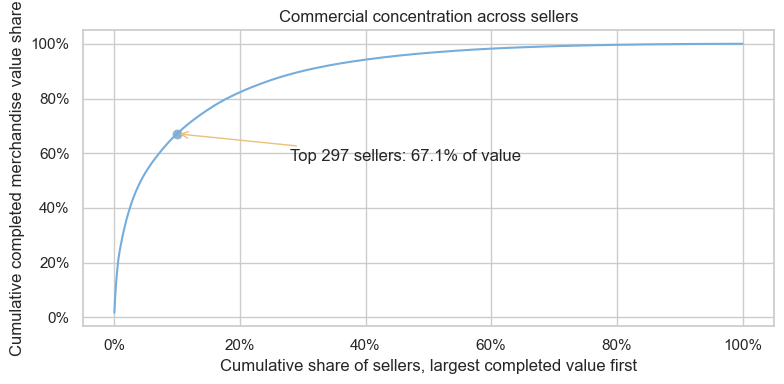

In [30]:
ranked_values = (
    seller_performance.merchandise_value
    .sort_values(
        ascending=False
    )
)

top10_n = int(
    np.ceil(
        len(ranked_values)
        * .10
    )
)

top10_share = (
    ranked_values
    .head(top10_n)
    .sum()
    / ranked_values.sum()
)

seller_concentration = pd.DataFrame(
    {
        'seller_share': (
            np.arange(
                1,
                len(ranked_values) + 1,
            )
            / len(ranked_values)
        ),
        'value_share': (
            ranked_values.cumsum().to_numpy()
            / ranked_values.sum()
        ),
    }
)

fig, ax = plt.subplots(
    figsize=(8, 4)
)

sns.lineplot(
    data=seller_concentration,
    x='seller_share',
    y='value_share',
    color="#75ADDC",
    ax=ax,
)

sns.scatterplot(
    x=[top10_n / len(ranked_values)],
    y=[top10_share],
    color='#8FB3D1',
    s=60,
    ax=ax,
)

ax.annotate(
    (
        f'Top {top10_n:,} sellers: '
        f'{top10_share:.1%} of value'
    ),
    xy=(
        top10_n / len(ranked_values),
        top10_share,
    ),
    xytext=(.28, .57),
    arrowprops={
        'arrowstyle': '->',
        'color': '#EBC07A',
    },
)


ax.xaxis.set_major_formatter(
    PercentFormatter(1)
)
ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.set(
    xlabel=(
        'Cumulative share of sellers, '
        'largest completed value first'
    ),
    ylabel=(
        'Cumulative completed '
        'merchandise value share'
    ),
    title='Commercial concentration across sellers',
)

fig.tight_layout()
plt.show()

save_figure(fig, 'seller_commercial_concentration')

#### Compare Seller Scale Across Category-Breadth Groups

Compare seller counts, median completed orders, and median completed merchandise value across four category-breadth groups: *Unknown only*, *1*, *2–3*, and *4+*. These broader groups summarize the relationship between observed category breadth and seller scale.


In [31]:
breadth_group = pd.cut(
    seller_performance.category_breadth,
    [
        -1,
        0,
        1,
        3,
        np.inf,
    ],
    labels=[
        'Unknown only',
        '1',
        '2–3',
        '4+',
    ],
)

breadth_summary = (
    seller_performance
    .groupby(
        breadth_group,
        observed=False,
    )
    .agg(
        sellers=('orders', 'size'),
        median_orders=(
            'orders',
            'median',
        ),
        median_value=(
            'merchandise_value',
            'median',
        ),
    )
)

display(breadth_summary)


,sellers,median_orders,median_value
category_breadth,,,
Unknown only,58,2.00,127.92
1,1636,3.00,397.80
2–3,878,11.00,"1,524.85"
4+,398,44.50,"4,935.32"


**Observation**

The median active seller records 7 completed orders and approximately BRL 846 in completed merchandise value, while 75% are observed in no more than 2 known product categories. Commercial activity is highly concentrated: the largest 10% of sellers by completed merchandise value account for about 68% of total completed value.

Sellers with broader observed category coverage tend to have higher completed-order counts and merchandise value. However, this relationship is descriptive, since higher-volume sellers also have more opportunities to be observed across multiple categories.

### 4. Delivery

**Describe lateness among completed orders with saved delivery attribution, then compare late-delivery rates across seller–customer distance bands and sellers.**

Lateness is measured using `order_estimated_delivery_date` as the available threshold. Orders delivered on or before the estimated date have zero `days_late`; orders delivered after that date have positive `days_late`. The analysis uses orders meeting the date eligibility conditions below.


#### Prepare Delivery-Attributable Orders

Filter the saved review-grain attribution table to delivery-attributable rows. Since multiple review rows may refer to the same order, verify that each order represented in the remaining rows has exactly one distinct seller before join the table to completed orders.

An order is eligible for lateness analysis when both delivery and estimated dates are present, the delivery timestamp is at or after the purchase timestamp, and the estimated calendar date is at or after the purchase calendar date.

In [32]:
review_entity_attribution = pd.read_parquet(
    PROCESSED_DIR / 'review_entity_attribution.parquet'
)

# Keep the review-grain rows first. The same order may appear more than once
# because one order can have multiple retained reviews.
delivery_review_links = (
    review_entity_attribution
    .loc[
        review_entity_attribution.delivery_attributable,
        [
            'order_id',
            'seller_id',
        ],
    ]
    .copy()
)

# Delivery-attributable orders must be attributable to one distinct seller,
# even though they may occupy multiple review-grain rows.
delivery_sellers_per_order = (
    delivery_review_links
    .groupby('order_id', observed=True)
    .seller_id
    .nunique()
)

ambiguous_delivery_orders = (
    delivery_sellers_per_order
    .loc[delivery_sellers_per_order.ne(1)]
)

assert ambiguous_delivery_orders.empty, (
    'Delivery-attributable orders must map to exactly one seller; '
    f'found {len(ambiguous_delivery_orders):,} conflicting orders.'
)

In [33]:
# Now change grain from review-level links to one row per attributable order.
delivery_attribution = (
    delivery_review_links
    .drop_duplicates(
        subset=[
            'order_id',
            'seller_id',
        ]
    )
    .reset_index(drop=True)
)

assert delivery_attribution.order_id.isin(
    order_context.order_id
).all()
assert delivery_attribution.seller_id.isin(
    seller_locations.index
).all()

delivery_orders = (
    completed_order_context[
        [
            'order_id',
            'customer_id',
            'order_purchase_timestamp',
            'order_delivered_customer_date',
            'order_estimated_delivery_date',
        ]
    ]
    .merge(
        delivery_attribution,
        on='order_id',
        how='inner',
        validate='1:1',
    )
)

delivery_orders['date_valid'] = (
    delivery_orders.order_delivered_customer_date.notna()
    & delivery_orders.order_estimated_delivery_date.notna()
    & delivery_orders.order_delivered_customer_date.ge(
        delivery_orders.order_purchase_timestamp
    )
    & delivery_orders.order_estimated_delivery_date
    .dt.normalize()
    .ge(
        delivery_orders.order_purchase_timestamp
        .dt.normalize()
    )
)

delivery_orders['days_late'] = (
    (
        delivery_orders.order_delivered_customer_date
        .dt.normalize()
        - delivery_orders.order_estimated_delivery_date
        .dt.normalize()
    )
    .dt.days
    .clip(lower=0) 
)

delivery_orders['late_delivery'] = (
    delivery_orders.days_late.gt(0)
)

valid_delivery = (
    delivery_orders
    .loc[delivery_orders.date_valid]
    .copy()
)

#### Describe Late-Delivery Outcomes

Summarize the frequency and severity of lateness among eligible attributable completed orders. The late-delivery rate uses all date-eligible orders, including on-time orders, as its denominator. The median, 90th percentile, and distribution of days late use late orders only.


In [34]:
late_delivery = (
    valid_delivery
    .loc[valid_delivery.late_delivery]
    .copy()
)

delivery_summary = pd.Series(
    {
        'attributable_completed_orders': len(
            delivery_orders
        ),
        'valid_delivered_orders': len(
            valid_delivery
        ),
        'late_delivery_orders': len(
            late_delivery
        ),
        'late_delivery_rate': (
            valid_delivery.late_delivery.mean()
        ),
        'median_days_late': (
            late_delivery.days_late.median()
        ),
        'p90_days_late': (
            late_delivery.days_late.quantile(.90)
        ),
    }
)

display(
    delivery_summary.to_frame('value')
)

,value
attributable_completed_orders,"93,544.00"
valid_delivered_orders,"93,536.00"
late_delivery_orders,"6,295.00"
late_delivery_rate,0.07
median_days_late,7.00
p90_days_late,22.00


Display lateness through 75 days in five-day bins, then combine all orders more than 75 days late into a final bar labelled `>75`. Values above 75 are mapped to 76 in the plotting column so that they fall into this overflow bin.


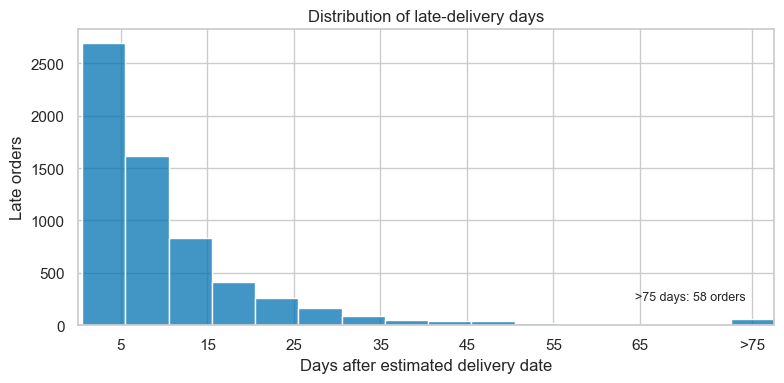

In [35]:
LATE_DAY_DISPLAY_MAX = 75

late_delivery_plot = (
    late_delivery
    .assign(
        days_late_plot=lambda d: (
            d.days_late
            .where(
                d.days_late.le(LATE_DAY_DISPLAY_MAX),
                LATE_DAY_DISPLAY_MAX + 1,
            )
        )
    )
)

overflow_orders = (
    late_delivery.days_late
    .gt(LATE_DAY_DISPLAY_MAX)
    .sum()
)

# Five-day bins through 75 days plus one final overflow bin.
hist_bins = np.append(
    np.arange(0.5, LATE_DAY_DISPLAY_MAX + 1, 5),
    LATE_DAY_DISPLAY_MAX + 5.5,
)

fig, ax = plt.subplots(
    figsize=(8, 4)
)

sns.histplot(
    data=late_delivery_plot,
    x='days_late_plot',
    bins=hist_bins,
    color=PALETTE[0],
    ax=ax,
)

ax.set_xticks(
    [5, 15, 25, 35, 45, 55, 65, 78],
    ['5', '15', '25', '35', '45', '55', '65', '>75'],
)
ax.set_xlim(0, LATE_DAY_DISPLAY_MAX + 5.5)

ax.set(
    xlabel='Days after estimated delivery date',
    ylabel='Late orders',
    title='Distribution of late-delivery days',
)

ax.annotate(
    f'>75 days: {overflow_orders:,} orders',
    xy=(78, 0),
    xycoords=('data', 'axes fraction'),
    xytext=(-5, 18),
    textcoords='offset points',
    ha='right',
    fontsize=9,
)

fig.tight_layout()
plt.show()


#### Relate Late Delivery to Seller–Customer Distance

Match cleaned customer and seller locations to the saved representative coordinates in `geo_lookup` using ZIP code prefix, state name, and municipality code. Location records marked `unresolved` are excluded from the coordinate joins. Lookup rows must have coordinates within the broad Brazil plausibility bounds used in the code.

Retain date-eligible orders with both customer and seller coordinate pairs available. Calculate their estimated distance using the Haversine formula. The following distance and seller comparisons use this subset of orders.


In [36]:
geo_keys = [
    'zip_code_prefix',
    'state_name',
    'municipality_full_code',
]

geo_lookup = pd.read_parquet(
    PROCESSED_DIR / 'geo_lookup.parquet'
)[
    geo_keys
    + [
        'representative_lat',
        'representative_lng',
    ]
]

customer_delivery_locations = pd.read_parquet(
    PROCESSED_DIR / 'customers_geo_processed.parquet'
)[
    geo_keys
    + [
        'geo_status',
    ]
]

seller_delivery_locations = pd.read_parquet(
    PROCESSED_DIR / 'sellers_geo_processed.parquet'
)[
    geo_keys
    + [
        'geo_status',
    ]
]

for frame in [
    geo_lookup,
    customer_delivery_locations,
    seller_delivery_locations,
]:
    frame['municipality_full_code'] = (
        frame.municipality_full_code
        .astype('Int64')
    )

assert not geo_lookup.duplicated(
    geo_keys
).any()

coordinate_plausible = (
    geo_lookup.representative_lat.between(
        -36,
        7,
    )
    & geo_lookup.representative_lng.between(
        -76,
        -30,
    )
)

usable_geo_lookup = (
    geo_lookup
    .loc[coordinate_plausible]
    .copy()
)

customer_coordinates = (
    customer_delivery_locations
    .loc[
        customer_delivery_locations.geo_status.ne(
            'unresolved'
        )
    ]
    .reset_index()
    .merge(
        usable_geo_lookup,
        on=geo_keys,
        how='left',
        validate='m:1',
    )
    .set_index('customer_id')
    [
        [
            'representative_lat',
            'representative_lng',
        ]
    ]
    .rename(
        columns={
            'representative_lat': 'customer_lat',
            'representative_lng': 'customer_lng',
        }
    )
)

seller_coordinates = (
    seller_delivery_locations
    .loc[
        seller_delivery_locations.geo_status.ne(
            'unresolved'
        )
    ]
    .reset_index()
    .merge(
        usable_geo_lookup,
        on=geo_keys,
        how='left',
        validate='m:1',
    )
    .set_index('seller_id')
    [
        [
            'representative_lat',
            'representative_lng',
        ]
    ]
    .rename(
        columns={
            'representative_lat': 'seller_lat',
            'representative_lng': 'seller_lng',
        }
    )
)

delivery_geo = (
    valid_delivery
    .merge(
        customer_coordinates,
        left_on='customer_id',
        right_index=True,
        how='left',
        validate='m:1',
    )
    .merge(
        seller_coordinates,
        left_on='seller_id',
        right_index=True,
        how='left',
        validate='m:1',
    )
)

distance_eligible = delivery_geo[
    [
        'customer_lat',
        'customer_lng',
        'seller_lat',
        'seller_lng',
    ]
].notna().all(axis=1)

distance_delivery = (
    delivery_geo
    .loc[distance_eligible]
    .copy()
)

EARTH_RADIUS_KM = 6_371.0088

customer_lat = np.radians(
    distance_delivery.customer_lat
)
customer_lng = np.radians(
    distance_delivery.customer_lng
)
seller_lat = np.radians(
    distance_delivery.seller_lat
)
seller_lng = np.radians(
    distance_delivery.seller_lng
)

lat_diff = customer_lat - seller_lat
lng_diff = customer_lng - seller_lng

haversine_a = (
    np.sin(lat_diff / 2) ** 2
    + np.cos(seller_lat)
    * np.cos(customer_lat)
    * np.sin(lng_diff / 2) ** 2
)

haversine_a = np.clip(
    haversine_a,
    0,
    1,
)

distance_delivery['distance_km'] = (
    2
    * EARTH_RADIUS_KM
    * np.arcsin(
        np.sqrt(haversine_a)
    )
)

print(
    f'Distance available for '
    f'{len(distance_delivery):,} / '
    f'{len(valid_delivery):,} '
    f'({len(distance_delivery) / len(valid_delivery):.1%}) '
    f'valid-lateness orders.'
)

print(
    f'Coordinate lookup rows excluded by the '
    f'plausibility check: '
    f'{(~coordinate_plausible).sum():,}'
)

Distance available for 91,612 / 93,536 (97.9%) valid-lateness orders.
Coordinate lookup rows excluded by the plausibility check: 5


Group eligible orders into distance-quantile bands, targeting five groups with approximately equal numbers of orders. For each band, calculate the late-delivery rate using all orders in that band. Plot this rate against the band's mean seller–customer distance.


,distance_group,orders,late_orders,mean_distance_km,late_delivery_rate_pct
0,"(-0.001, 112.305]",18323,832,43.60,4.54
1,"(112.305, 347.358]",18322,1043,250.65,5.69
2,"(347.358, 529.536]",18322,1220,432.63,6.66
3,"(529.536, 876.34]",18322,1306,697.38,7.13
4,"(876.34, 3710.425]",18323,1763,"1,577.19",9.62


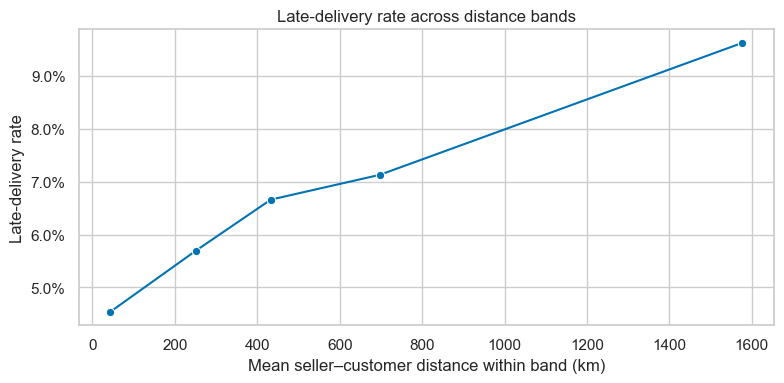

In [37]:
N_DISTANCE_GROUPS = 5

distance_delivery['distance_group'] = pd.qcut(
    distance_delivery.distance_km,
    q=N_DISTANCE_GROUPS,
    duplicates='drop',
)

distance_summary = (
    distance_delivery
    .groupby(
        'distance_group',
        observed=True,
    )
    .agg(
        orders=('order_id', 'size'),
        late_orders=(
            'late_delivery',
            'sum',
        ),
        mean_distance_km=(
            'distance_km',
            'mean',
        ),
        late_delivery_rate=(
            'late_delivery',
            'mean',
        ),
    )
    .reset_index()
)

assert distance_summary.orders.sum() == len(
    distance_delivery
)

display(
    distance_summary.assign(
        late_delivery_rate_pct=lambda d: (
            d.late_delivery_rate * 100
        )
    )
    [
        [
            'distance_group',
            'orders',
            'late_orders',
            'mean_distance_km',
            'late_delivery_rate_pct',
        ]
    ]
)

fig, ax = plt.subplots(
    figsize=(8, 4)
)

sns.lineplot(
    data=distance_summary,
    x='mean_distance_km',
    y='late_delivery_rate',
    marker='o',
    color=PALETTE[0],
    ax=ax,
)

ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.set(
    xlabel='Mean seller–customer distance within band (km)',
    ylabel='Late-delivery rate',
    title='Late-delivery rate across distance bands',
)

fig.tight_layout()
plt.show()

save_figure(fig, 'late_delivery_rate_by_distance')

#### Inspect Seller-Associated Late-Delivery Patterns

Use the previous calculated mean late-delivery rate in each distance band as a descriptive benchmark. Assign each eligible order its band's rate, then average those rates within each seller. The resulting `distance_expected_late_rate` weights the band rates by that seller's order mix. Compare it with the seller's observed late-delivery rate; `excess_late_rate` is observed rate minus benchmark rate.

Restrict the seller comparison to sellers with at least 30 distance-eligible orders to reduce instability from very small denominators. 

In [38]:
distance_rate_lookup = (
    distance_summary
    .set_index('distance_group')
    .late_delivery_rate
)

distance_delivery[
    'distance_expected_late_rate'
] = (
    distance_delivery.distance_group
    .map(distance_rate_lookup)
    .astype(float)
)

seller_delivery_summary = (
    distance_delivery
    .groupby('seller_id')
    .agg(
        valid_distance_orders=(
            'order_id',
            'size',
        ),
        late_delivery_orders=(
            'late_delivery',
            'sum',
        ),
        late_delivery_rate=(
            'late_delivery',
            'mean',
        ),
        distance_expected_late_rate=(
            'distance_expected_late_rate',
            'mean',
        ),
    )
)

seller_delivery_summary[
    'excess_late_rate'
] = (
    seller_delivery_summary.late_delivery_rate
    - seller_delivery_summary.distance_expected_late_rate
)

MIN_SELLER_DELIVERY_ORDERS = 30

seller_rate_population = (
    seller_delivery_summary
    .loc[
        seller_delivery_summary.valid_distance_orders.ge(
            MIN_SELLER_DELIVERY_ORDERS
        )
    ]
    .copy()
)

print(
    f'{len(seller_rate_population):,} sellers have at least '
    f'{MIN_SELLER_DELIVERY_ORDERS} distance-eligible orders; '
    f'they cover '
    f'{seller_rate_population.valid_distance_orders.sum() / len(distance_delivery):.1%} '
    f'of distance-eligible orders.'
)

594 sellers have at least 30 distance-eligible orders; they cover 83.0% of distance-eligible orders.


Group the selected sellers into order-volume quartiles. Larger-volume groups are drawn first as larger, paler circles; lower-volume groups are drawn afterward in stronger colors. Short seller IDs label the five sellers with the highest observed late-delivery rates among those plotted.

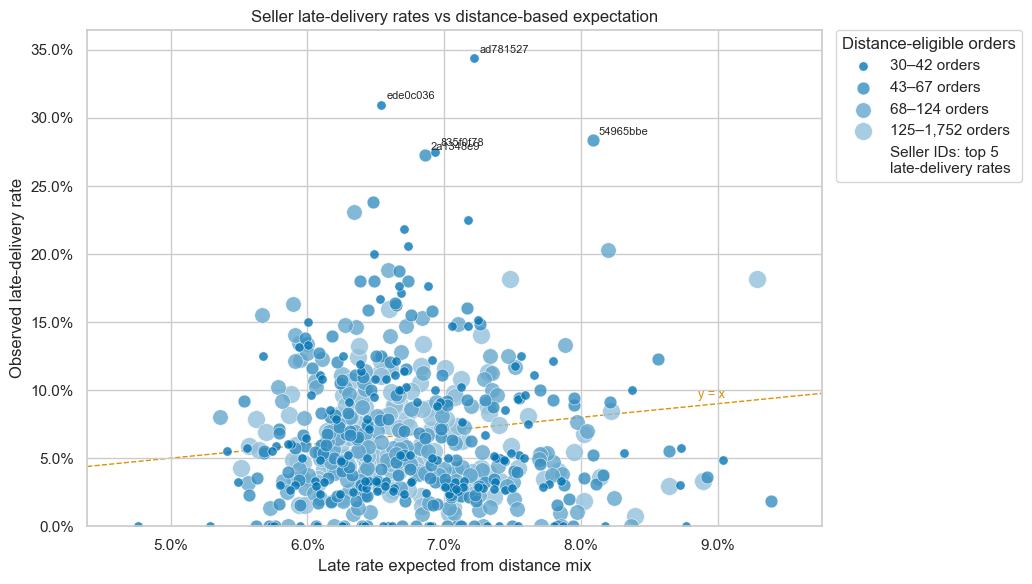

In [39]:
seller_rate_population['order_volume_group'] = pd.qcut(
    seller_rate_population.valid_distance_orders,
    q=4,
    duplicates='drop',
)

volume_groups = list(
    seller_rate_population.order_volume_group
    .cat.categories
)

volume_colors = sns.light_palette(
    PALETTE[0],
    n_colors=len(volume_groups) + 2,
    reverse=True,
)[:len(volume_groups)]

volume_sizes = np.linspace(
    45,
    165,
    len(volume_groups),
)

fig, ax = plt.subplots(
    figsize=(10.5, 6)
)

legend_handles = []
legend_labels = []

for group_idx in reversed(range(len(volume_groups))):
    group = volume_groups[group_idx]
    group_data = seller_rate_population.loc[
        seller_rate_population.order_volume_group.eq(group)
    ]

    order_min = int(
        group_data.valid_distance_orders.min()
    )
    order_max = int(
        group_data.valid_distance_orders.max()
    )
    group_label = (
        f'{order_min:,}–{order_max:,} orders'
        if order_min != order_max
        else f'{order_min:,} orders'
    )

    scatter = ax.scatter(
        group_data.distance_expected_late_rate,
        group_data.late_delivery_rate,
        s=volume_sizes[group_idx],
        color=volume_colors[group_idx],
        alpha=.78,
        marker='o',
        edgecolors='white',
        linewidths=.45,
        label=group_label,
    )

    legend_handles.append(scatter)
    legend_labels.append(group_label)

# Scale x and y independently. This preserves all sellers but centers the
# figure on the actual expected-rate range instead of forcing a square 0--max
# frame determined by the much wider observed-rate range.
x_min_data = (
    seller_rate_population.distance_expected_late_rate.min()
)
x_max_data = (
    seller_rate_population.distance_expected_late_rate.max()
)
x_span = max(
    x_max_data - x_min_data,
    .005,
)

x_min = max(
    0,
    x_min_data - .08 * x_span,
)
x_max = x_max_data + .08 * x_span

y_max = (
    seller_rate_population.late_delivery_rate.max()
    * 1.06
)

# Reference line for observed = distance-based expected rate.
reference_start = max(0, x_min)
reference_end = min(x_max, y_max)

ax.plot(
    [reference_start, reference_end],
    [reference_start, reference_end],
    linestyle='--',
    color=PALETTE[1],
    linewidth=1,
    zorder=0,
)

# Label the equality reference explicitly because the x- and y-axis
# scales differ, so y = x does not appear as a 45-degree line.
label_x = (
    reference_start
    + .82 * (reference_end - reference_start)
)

ax.annotate(
    'y = x',
    xy=(label_x, label_x),
    xytext=(6, 4),
    textcoords='offset points',
    color=PALETTE[1],
    fontsize=9,
    ha='left',
    va='bottom',
)

for seller_id, row in (
    seller_rate_population
    .nlargest(
        5,
        'late_delivery_rate',
    )
    .iterrows()
):
    ax.annotate(
        seller_id[:8],
        xy=(
            row.distance_expected_late_rate,
            row.late_delivery_rate,
        ),
        xytext=(4, 4),
        textcoords='offset points',
        fontsize=8,
    )

ax.set_xlim(x_min, x_max)
ax.set_ylim(0, y_max)

ax.xaxis.set_major_formatter(
    PercentFormatter(1)
)
ax.yaxis.set_major_formatter(
    PercentFormatter(1)
)

ax.set(
    xlabel='Late rate expected from distance mix',
    ylabel='Observed late-delivery rate',
    title=(
        'Seller late-delivery rates vs '
        'distance-based expectation'
    ),
)

# Restore the legend in ascending order-volume order even though high-volume
# groups were drawn first to keep large pale circles in the background.
seller_id_note = Line2D([], [], linestyle='none')

ax.legend(
    handles=legend_handles[::-1] + [seller_id_note],
    labels=legend_labels[::-1] + [
        'Seller IDs: top 5\nlate-delivery rates',
    ],
    title='Distance-eligible orders',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    frameon=True,
)

fig.tight_layout()
plt.show()

save_figure(fig, 'seller_late_rate_vs_distance_expectation')

**Observation**

Late-delivery rates increase from about 4.5% to 9.6% across the five distance bands, showing an association between greater seller–customer distance and more frequent delays.

The scatterplot shows substantial differences between sellers with similar distance-based benchmarks, with observed late-delivery rates ranging from near zero to above 30%. Delivery performance therefore varies considerably across sellers beyond what the distance-based benchmark captures, although sampling variation and other factors may also contribute.

## **Customer Experience Analysis**

This section examines Product, Seller, and Delivery experience using the saved constructed scores. For these dimensions, the latest non-null score is selected independently within each order and dimension, preserving its source review. Dimension-specific attribution and timing rules then define the analytical populations.   

Overall Experience is analyzed separately using the original customer rating across the full review table. Original ratings are not subjected to the latest-per-dimension selection rule.

### 1. Review Population and Score Selection

**Attach the saved scores, retain the latest available evaluation within
each order and dimension, and preserve the original review provenance.**

#### Attach Saved Category Scores

The saved attribution table (`review_entity_attribution`) contains one retained review per unique review_id; each retained review maps unambiguously to one order, although an order may have more than one retained review.
category_scores contains one row per Portuguese review text and dimension. Pivot this unique text–dimension key without aggregation to obtain Product, Seller, and Delivery score columns, then attach them to the retained reviews through the original Portuguese review text. Finally, identify the orders with at least one non-null constructed dimension score. These orders define the population eligible for the subsequent Customer Experience score-selection step.


In [40]:


category_scores = pd.read_csv(
    PROCESSED_DIR / 'categorized_score.csv',
    usecols=['review_pt', 'category', 'score'],
)

DIMENSIONS = ['product', 'seller', 'delivery']
score_columns = [dimension + '_score' for dimension in DIMENSIONS]


dimension_score_lookup = (
    category_scores
    .pivot(
        index='review_pt',
        columns='category',
        values='score',
    )
    .reindex(columns=DIMENSIONS)
    .add_suffix('_score')
    .rename_axis(columns=None)
)

retained_reviews = (
    review_entity_attribution[['order_id']]
    .reset_index()
    .merge(
        review_df,
        on=['review_id', 'order_id'],
        how='left',
        validate='1:1',
        indicator=True,
    )
)

assert retained_reviews._merge.eq('both').all()
retained_reviews = retained_reviews.drop(columns='_merge')

review_score_candidates = retained_reviews.merge(
    dimension_score_lookup,
    left_on='review_comment_message',
    right_index=True,
    how='left',
    validate='m:1',
)


scored_review_mask = review_score_candidates[score_columns].notna().any(
    axis=1
)
scored_order_ids = pd.Index(
    review_score_candidates.loc[scored_review_mask, 'order_id'].unique(),
    name='order_id',
)


#### Select the Latest Non-Null Score Within Each Dimension

Change from review grain to one selected evaluation per `(order_id, dimension)`. Use the review answer timestamp to order submissions, after excluding null scores separately within each dimension. A later review that does not evaluate a dimension therefore cannot erase its earlier score.

Keep the source review ID with each selected score. For every (order_id, dimension), verify that exactly one review has the latest timestamp and that each order–dimension with at least one non-null candidate score produces exactly one selected score. Original customer ratings are not part of this selection.

In [41]:
dimension_candidates = (
    review_score_candidates
    .melt(
        id_vars=[
            'order_id',
            'review_id',
            'review_answer_timestamp',
        ],
        value_vars=score_columns,
        var_name='dimension',
        value_name='score',
    )
    .dropna(subset=['score'])
    .rename(columns={'review_id': 'source_review_id'})
)

dimension_candidates['dimension'] = (
    dimension_candidates.dimension.str.removesuffix('_score')
)
selection_keys = ['order_id', 'dimension']

latest_dimension_times = (
    dimension_candidates
    .groupby(selection_keys)
    .review_answer_timestamp.max()
    .rename('latest_timestamp')
)

dimension_candidates = dimension_candidates.join(
    latest_dimension_times,
    on=selection_keys,
    validate='m:1',
)

selected_dimension_scores = (
    dimension_candidates
    .loc[
        dimension_candidates.review_answer_timestamp.eq(
            dimension_candidates.latest_timestamp
        ),
        [
            'order_id',
            'dimension',
            'source_review_id',
            'review_answer_timestamp',
            'score',
        ],
    ]
    .copy()
)

assert not selected_dimension_scores.duplicated(selection_keys).any(), (
    'A latest timestamp is shared by multiple reviews for one dimension; '
    'inspect its provenance before selecting a score.'
)
assert len(selected_dimension_scores) == len(latest_dimension_times)
assert selected_dimension_scores.score.notna().all()
assert pd.Index(
    selected_dimension_scores.order_id.unique()
).sort_values().equals(scored_order_ids.sort_values())

selection_check = (
    selected_dimension_scores
    .set_index(selection_keys)
    .join(latest_dimension_times, validate='1:1')
)
assert selection_check.review_answer_timestamp.eq(
    selection_check.latest_timestamp
).all()

latest_order_times = (
    review_score_candidates
    .groupby('order_id')
    .review_answer_timestamp.max()
)

selection_diagnostics = pd.DataFrame(index=DIMENSIONS)
selection_diagnostics.index.name = 'dimension'
selection_diagnostics['candidate_evaluations'] = (
    dimension_candidates.groupby('dimension').size()
)
selection_diagnostics['selected_orders'] = (
    selected_dimension_scores.groupby('dimension').size()
)
selection_diagnostics['older_evaluations_removed'] = (
    selection_diagnostics.candidate_evaluations
    - selection_diagnostics.selected_orders
)
selection_diagnostics['preserved_before_later_null_review'] = (
    selected_dimension_scores
    .assign(
        before_latest_review=lambda d: (
            d.review_answer_timestamp.lt(
                d.order_id.map(latest_order_times)
            )
        )
    )
    .groupby('dimension')
    .before_latest_review.sum()
)

display(selection_diagnostics)


,candidate_evaluations,selected_orders,older_evaluations_removed,preserved_before_later_null_review
dimension,,,,
product,13290,13288,2,6
seller,14314,14313,1,11
delivery,19149,19142,7,8


#### Prepare the Shared Order-Level Base

Pivot the selected evaluations to one row per order, keeping a separate
source review ID for each dimension. Reduce the saved attribution to order
grain only after verifying that its entity IDs and attribution flags agree
across reviews of the same order. Both this attachment and the order-context
attachment are one-to-one joins.

Use the selected Product review's timestamp to establish receipt before
evaluation, and the selected Delivery review's timestamp to distinguish
pre-delivery from post-delivery assessments. Raw text and timestamps do not
enter the final shared base.


In [42]:
order_attribution_columns = [
    'product_id',
    'seller_id',
    'product_attributable',
    'seller_attributable',
    'delivery_attributable',
]

attribution_consistency = (
    review_entity_attribution
    .groupby('order_id')[order_attribution_columns]
    .nunique(dropna=False)
)
assert attribution_consistency.eq(1).all().all()

order_attribution = (
    review_entity_attribution[
        ['order_id'] + order_attribution_columns
    ]
    .drop_duplicates('order_id')
)
assert order_attribution.order_id.is_unique

selected_scores_wide = (
    selected_dimension_scores
    .pivot(index='order_id', columns='dimension', values='score')
    .reindex(columns=DIMENSIONS)
    .add_suffix('_score')
    .rename_axis(columns=None)
)

selected_sources_wide = (
    selected_dimension_scores
    .pivot(
        index='order_id',
        columns='dimension',
        values='source_review_id',
    )
    .reindex(columns=DIMENSIONS)
    .add_suffix('_review_id')
    .rename_axis(columns=None)
)

selected_times_wide = (
    selected_dimension_scores
    .pivot(
        index='order_id',
        columns='dimension',
        values='review_answer_timestamp',
    )
    .reindex(columns=['product', 'delivery'])
    .add_suffix('_review_submitted_at')
    .rename_axis(columns=None)
)

review_order_base = (
    selected_scores_wide
    .join(selected_sources_wide, validate='1:1')
    .join(selected_times_wide, validate='1:1')
    .reset_index()
    .merge(
        order_attribution,
        on='order_id',
        how='left',
        validate='1:1',
    )
    .merge(
        order_context[
            [
                'order_id',
                'order_status',
                'order_purchase_timestamp',
                'order_delivered_customer_date',
            ]
        ],
        on='order_id',
        how='left',
        validate='1:1',
    )
)

assert len(review_order_base) == len(scored_order_ids)
assert review_order_base.order_id.is_unique
assert review_order_base[score_columns].notna().any(axis=1).all()
assert review_order_base.order_status.notna().all()
assert review_order_base[
    [dimension + '_attributable' for dimension in DIMENSIONS]
].notna().all().all()

actual_delivery_valid = (
    review_order_base.order_delivered_customer_date.notna()
    & review_order_base.order_delivered_customer_date.ge(
        review_order_base.order_purchase_timestamp
    )
)

review_order_base['product_received_before_review'] = (
    review_order_base.order_status.eq('delivered')
    & actual_delivery_valid
    & review_order_base.product_review_submitted_at.ge(
        review_order_base.order_delivered_customer_date
    )
)

delivery_timing_available = (
    actual_delivery_valid
    & review_order_base.delivery_review_submitted_at.notna()
)
review_order_base['delivery_review_before_delivery'] = pd.Series(
    pd.NA,
    index=review_order_base.index,
    dtype='boolean',
)
review_order_base.loc[
    delivery_timing_available,
    'delivery_review_before_delivery',
] = (
    review_order_base.loc[
        delivery_timing_available,
        'delivery_review_submitted_at',
    ]
    .lt(
        review_order_base.loc[
            delivery_timing_available,
            'order_delivered_customer_date',
        ]
    )
)

product_lifecycle_check = (
    review_order_base
    .assign(
        scored=lambda d: d.product_score.notna(),
        attributable_score=lambda d: (
            d.product_score.notna() & d.product_attributable
        ),
        valid_receipt=lambda d: (
            d.product_score.notna()
            & d.product_attributable
            & d.order_status.eq('delivered')
            & actual_delivery_valid
        ),
        eligible=lambda d: (
            d.product_score.notna()
            & d.product_attributable
            & d.product_received_before_review
        ),
    )
    .groupby('order_status')
    .agg(
        scored_orders=('scored', 'sum'),
        attributable_orders=('attributable_score', 'sum'),
        valid_receipt_orders=('valid_receipt', 'sum'),
        eligible_orders=('eligible', 'sum'),
    )
)

review_order_base = review_order_base.drop(
    columns=[
        'product_review_submitted_at',
        'delivery_review_submitted_at',
        'order_purchase_timestamp',
        'order_delivered_customer_date',
    ]
)

for dimension in DIMENSIONS:
    score_present = review_order_base[dimension + '_score'].notna()
    source_present = review_order_base[dimension + '_review_id'].notna()
    assert score_present.equals(source_present)
    target = 'product_id' if dimension == 'product' else 'seller_id'
    assert review_order_base.loc[
        review_order_base[dimension + '_attributable'], target
    ].notna().all()



In [43]:
review_population_summary = pd.Series(
    {
        'all_review_records': len(review_df),
        'attribution_retained_reviews': len(retained_reviews),
        'orders_after_latest_dimension_selection': len(review_order_base),
    },
    name='count',
)

dimension_coverage_rows = []
for dimension in DIMENSIONS:
    scored = review_order_base[dimension + '_score'].notna()
    attributable = review_order_base[dimension + '_attributable']
    dimension_coverage_rows.append(
        {
            'dimension': dimension,
            'selected_score_orders': int(scored.sum()),
            'attributable_score_orders': int(
                (scored & attributable).sum()
            )
        }
    )

dimension_coverage = (
    pd.DataFrame(dimension_coverage_rows)
    .set_index('dimension')
)

display(review_population_summary.to_frame())
display(dimension_coverage)


,count
all_review_records,99224
attribution_retained_reviews,97621
orders_after_latest_dimension_selection,32703


,selected_score_orders,attributable_score_orders
dimension,,
product,13288,12933
seller,14313,13489
delivery,19142,18572


**Observation**

Among the attribution-retained reviews, 32,703 orders contain at least one selected Product, Seller, or Delivery score after the independent latest-score selection. Independent latest-score selection preserves all of these orders while removing 2 superseded Product, 1 Seller, and 7 Delivery evaluations. It also preserves earlier non-null evaluations where a later review omits the dimension: 6 Product, 11 Seller, and 8 Delivery cases.


### 2. Product Experience

**Describe evaluations of received products and compare product categories with sufficient reviewed orders.**

#### Establish Receipt Before Evaluation

Inspect selected Product-score coverage by order status before applying the primary eligibility rule. Require Product attribution, delivered status, an actual delivery timestamp no earlier than purchase, and submission of
the selected Product review on or after delivery. This population does not depend on Delivery attribution, estimated dates, or coordinates.

In [44]:
display(product_lifecycle_check)

product_experience = (
    review_order_base
    .loc[
        review_order_base.product_score.notna()
        & review_order_base.product_attributable
        & review_order_base.product_received_before_review,
        [
            'order_id',
            'product_review_id',
            'product_id',
            'product_score',
        ],
    ]
    .copy()
)

assert product_experience.product_id.isin(products.index).all()
product_experience = product_experience.merge(
    products[['product_category_name']],
    left_on='product_id',
    right_index=True,
    how='left',
    validate='m:1',
).rename(columns={'product_category_name': 'category'})

product_experience['category'] = (
    product_experience.category.fillna(UNCATEGORIZED)
)

assert product_experience.order_id.is_unique
assert product_experience.product_review_id.is_unique
assert len(product_experience) == product_lifecycle_check.eligible_orders.sum()

product_experience_summary = pd.Series(
    {
        'usable_evaluations': len(product_experience),
        'reviewed_orders': product_experience.order_id.nunique(),
        'mean_product_score': product_experience.product_score.mean(),
        'low_score_share': product_experience.product_score.lt(3).mean(),
    }
)
display(product_experience_summary.to_frame('value'))


,scored_orders,attributable_orders,valid_receipt_orders,eligible_orders
order_status,,,,
canceled,23,6,0,0
created,0,0,0,0
delivered,13225,12897,12895,12805
invoiced,9,9,0,0
processing,2,2,0,0
shipped,19,19,0,0
unavailable,10,0,0,0


,value
usable_evaluations,"12,805.00"
reviewed_orders,"12,805.00"
mean_product_score,3.91
low_score_share,0.26


#### Describe Product Scores

Plot the selected eligible Product scores on their original scale. Narrow
histogram bins retain the fractional values produced by aspect aggregation;
the scores are not rounded into integer ratings.


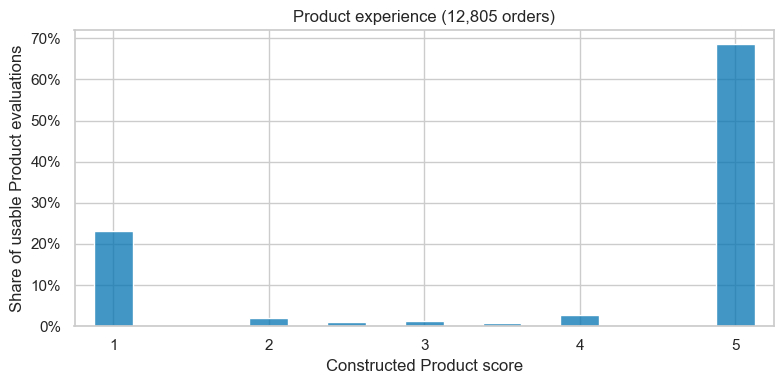

In [45]:
EXPERIENCE_SCORE_BINS = np.arange(0.875, 5.126, 0.25)

fig, ax = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=product_experience,
    x='product_score',
    bins=EXPERIENCE_SCORE_BINS,
    stat='percent',
    color=PALETTE[0],
    ax=ax,
)

ax.set(
    xlabel='Constructed Product score',
    ylabel='Share of usable Product evaluations',
    title=f'Product experience ({len(product_experience):,} orders)',
    xticks=[1, 2, 3, 4, 5],
    xlim=(0.75, 5.25),
)
ax.yaxis.set_major_formatter(PercentFormatter(100))

fig.tight_layout()
plt.show()


#### Compare Product Categories

Aggregate eligible evaluations to category grain. Keep every category from the cleaned reference, including categories with no usable evaluations; their counts are zero and their experience measures remain missing.

For comparison only, require at least 30 distinct reviewed orders and exclude `Uncategorized`. Display up to six categories with the lowest mean Product scores and six categories with the highest, together with their reviewed-order counts. The 30-reviewed-order threshold is applied only to the comparison subset; category_experience continues to retain all categories and their available experience measures

In [46]:
category_experience = (
    product_experience
    .groupby('category')
    .agg(
        product_reviews=('product_review_id', 'size'),
        product_review_orders=('order_id', 'nunique'),
        mean_product_score=('product_score', 'mean'),
        low_product_score_share=(
            'product_score',
            lambda s: s.lt(3).mean(),
        ),
    )
)

category_reference = pd.Index(
    products.product_category_name.fillna(UNCATEGORIZED).unique(),
    name='category',
).sort_values()

category_experience = category_experience.reindex(category_reference)
category_count_columns = ['product_reviews', 'product_review_orders']
category_experience[category_count_columns] = (
    category_experience[category_count_columns]
    .fillna(0)
    .astype(int)
)

assert category_experience.index.is_unique
assert category_experience.product_reviews.sum() == len(product_experience)
assert category_experience.product_reviews.equals(
    category_experience.product_review_orders
)

MIN_CATEGORY_REVIEW_ORDERS = 30
categories_for_comparison = (
    category_experience
    .loc[
        category_experience.product_review_orders.ge(
            MIN_CATEGORY_REVIEW_ORDERS
        )
        & category_experience.index.to_series().ne(UNCATEGORIZED)
    ]
    .copy()
)

comparison_categories = (
    categories_for_comparison.nsmallest(6, 'mean_product_score').index
    .union(
        categories_for_comparison.nlargest(6, 'mean_product_score').index,
        sort=False,
    )
)
category_experience_comparison = (
    categories_for_comparison
    .loc[comparison_categories]
    .sort_values('mean_product_score')
)

known_product_reviews = category_experience.drop(
    index=UNCATEGORIZED
).product_reviews.sum()
comparison_category_review_share = (
    categories_for_comparison.product_reviews.sum() / known_product_reviews
)

print(
    f'{len(categories_for_comparison):,} named categories meet the '
    f'{MIN_CATEGORY_REVIEW_ORDERS}-order rule; they cover '
    f'{comparison_category_review_share:.1%} '
    f'of usable Product evaluations with a known category.'
)
display(category_experience_comparison)


38 named categories meet the 30-order rule; they cover 97.2% of usable Product evaluations with a known category.


,product_reviews,product_review_orders,mean_product_score,low_product_score_share
category,,,,
office_furniture,222,222,2.99,0.50
audio,61,61,3.09,0.48
kitchen_dining_laundry_garden_furniture,38,38,3.33,0.42
telephony,621,621,3.45,0.38
computers_accessories,756,756,3.58,0.35
home_confort,72,72,3.62,0.33
sports_leisure,712,712,4.17,0.20
luggage_accessories,170,170,4.29,0.17
garden_tools,501,501,4.34,0.16


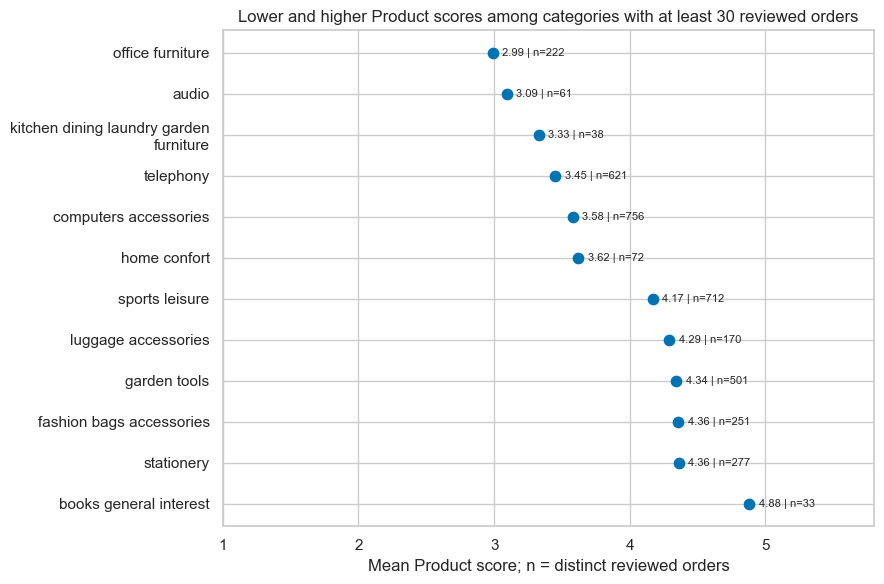

In [47]:
category_experience_plot = category_experience_comparison.reset_index()
category_experience_plot['category_label'] = (
    category_experience_plot.category
    .str.replace('_', ' ', regex=False)
    .str.wrap(32)
)

fig, ax = plt.subplots(figsize=(9, 6))
y_positions = np.arange(len(category_experience_plot))

ax.scatter(
    category_experience_plot.mean_product_score,
    y_positions,
    color=PALETTE[0],
    s=55,
)

for position, row in enumerate(
    category_experience_plot.itertuples(index=False)
):
    ax.annotate(
        f'{row.mean_product_score:.2f} | n={row.product_review_orders:,}',
        xy=(row.mean_product_score, position),
        xytext=(7, 0),
        textcoords='offset points',
        va='center',
        fontsize=8,
    )

ax.set_yticks(y_positions, category_experience_plot.category_label)
ax.invert_yaxis()
ax.set(
    xlabel='Mean Product score; n = distinct reviewed orders',
    ylabel='',
    title='Lower and higher Product scores among categories with at least 30 reviewed orders',
    xlim=(1, 5.8),
    xticks=[1, 2, 3, 4, 5],
)

fig.tight_layout()
plt.show()

save_figure(fig, 'product_experience_by_category')

**Observation**

The primary Product population contains 12,805 selected evaluations, with a
mean score of 3.91; 68.5% score 5 and 26.3% fall below 3. Receipt checks
exclude 36 attributable evaluations on non-delivered orders, 2 delivered
orders without valid receipt timestamps, and 90 evaluations submitted
before recorded receipt.

Among categories meeting the 30-order rule, office furniture has the lowest
mean Product score (2.99; 222 orders). Telephony also receives comparatively
low evaluations (3.45; 621 orders). Books of general interest has the
highest mean (4.88), based on only 33 orders. These comparisons describe
the eligible reviewed orders; reviewed-order counts still differs considerably across
categories.


### 3. Seller Experience

**Describe Seller evaluations across lifecycle outcomes, then compare sellers with at least 10 reviewed orders.**

Retain selected Seller scores with valid seller attribution, including non-delivered orders. 

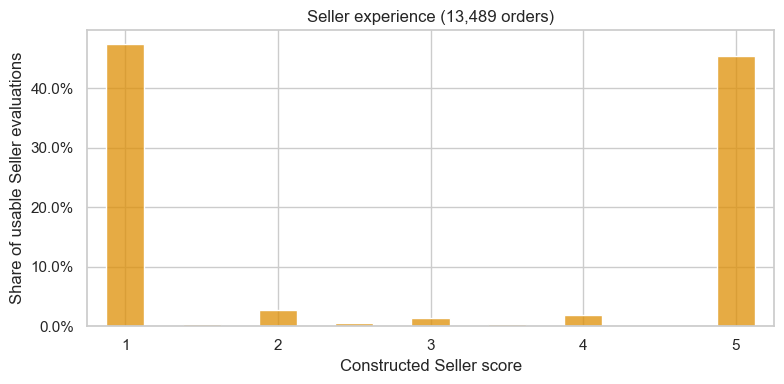

In [48]:
seller_experience = (
    review_order_base
    .loc[
        review_order_base.seller_score.notna()
        & review_order_base.seller_attributable,
        [
            'order_id',
            'seller_review_id',
            'seller_id',
            'seller_score',
            'order_status',
        ],
    ]
    .copy()
)

seller_experience['non_delivered'] = (
    seller_experience.order_status.ne('delivered')
)

seller_status_summary = (
    seller_experience
    .groupby('order_status')
    .agg(
        seller_reviews=('seller_review_id', 'size'),
        reviewed_orders=('order_id', 'nunique'),
        mean_seller_score=('seller_score', 'mean'),
        low_score_share=('seller_score', lambda s: s.lt(3).mean()),
    )
    .sort_values('seller_reviews', ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=seller_experience,
    x='seller_score',
    bins=EXPERIENCE_SCORE_BINS,
    stat='percent',
    color=PALETTE[1],
    ax=ax,
)

ax.set(
    xlabel='Constructed Seller score',
    ylabel='Share of usable Seller evaluations',
    title=f'Seller experience ({len(seller_experience):,} orders)',
    xticks=[1, 2, 3, 4, 5],
    xlim=(0.75, 5.25),
)
ax.yaxis.set_major_formatter(PercentFormatter(100))

fig.tight_layout()
plt.show()

Compare Seller scores across recorded order statuses. These are the available lifecycle outcomes, not necessarily the status at the time the
review was submitted. Keep reviewed-order counts visible, especially for rare order statuses.


In [49]:
display(seller_status_summary)

,seller_reviews,reviewed_orders,mean_seller_score,low_score_share
order_status,,,,
delivered,12949,12949,3.01,0.49
shipped,211,211,1.45,0.88
canceled,144,144,1.25,0.92
invoiced,93,93,1.34,0.90
processing,89,89,1.08,0.98
unavailable,3,3,1.00,1.00


#### Examine Seller-Level Review Counts and Evaluations

Build one row per seller with usable evaluations, keeping every such seller in the summary. Count both selected Seller evaluations and distinct reviewed orders; these coincide after the independent latest-score selection.

Inspect the distribution of reviewed-order counts before restricting the comparison to sellers with at least 10 reviewed orders. This threshold is used only for the comparison and does not filter the underlying seller summary or introduce commercial-performance measures.

In [50]:
seller_experience_summary = (
    seller_experience
    .groupby('seller_id')
    .agg(
        seller_reviews=('seller_review_id', 'size'),
        seller_review_orders=('order_id', 'nunique'),
        mean_seller_score=('seller_score', 'mean'),
        low_seller_score_share=(
            'seller_score',
            lambda s: s.lt(3).mean(),
        ),
        non_delivered_review_share=('non_delivered', 'mean'),
    )
)


seller_review_order_band = pd.cut(
    seller_experience_summary.seller_review_orders,
    bins=[0, 1, 4, 9, 19, 49, np.inf],
    labels=['1', '2–4', '5–9', '10–19', '20–49', '50+'],
)

seller_review_count_distribution = (
    seller_experience_summary
    .groupby(seller_review_order_band, observed=False)
    .agg(
        sellers=('seller_reviews', 'size'),
        evaluations=('seller_reviews', 'sum'),
    )
    .rename_axis('reviewed_orders_per_seller')
)

seller_review_count_distribution['seller_share'] = (
    seller_review_count_distribution.sellers
    / len(seller_experience_summary)
)

display(seller_review_count_distribution)

MIN_SELLER_REVIEW_ORDERS = 10

seller_experience_comparison = (
    seller_experience_summary
    .loc[
        seller_experience_summary.seller_review_orders.ge(
            MIN_SELLER_REVIEW_ORDERS
        )
    ]
    .copy()
)

comparison_evaluation_share = (
    seller_experience_comparison.seller_reviews.sum()
    / len(seller_experience)
)

print(
    f'{len(seller_experience_comparison):,} / '
    f'{len(seller_experience_summary):,} evaluated sellers meet the '
    f'{MIN_SELLER_REVIEW_ORDERS}-order rule; they account for '
    f'{comparison_evaluation_share:.1%} '
    f'of usable Seller evaluations.'
)

,sellers,evaluations,seller_share
reviewed_orders_per_seller,,,
1,645,645,0.36
2–4,573,1570,0.32
5–9,268,1735,0.15
10–19,183,2516,0.10
20–49,93,2745,0.05
50+,41,4278,0.02


317 / 1,803 evaluated sellers meet the 10-order rule; they account for 70.7% of usable Seller evaluations.


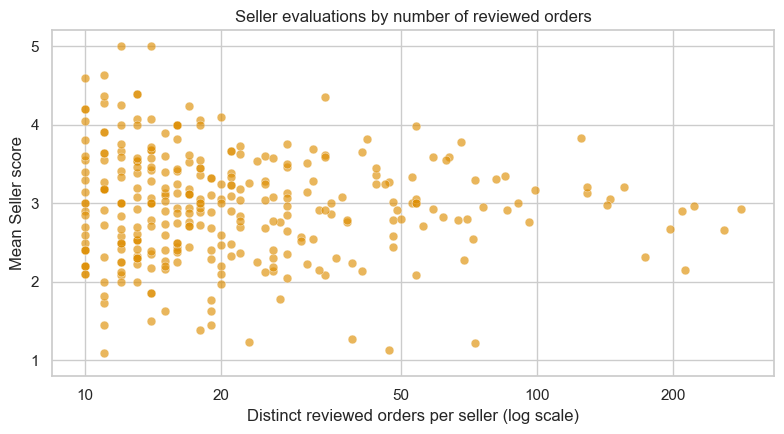

In [51]:
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.scatterplot(
    data=seller_experience_comparison,
    x='seller_review_orders',
    y='mean_seller_score',
    color=PALETTE[1],
    alpha=0.65,
    s=40,
    edgecolor='white',
    linewidth=0.4,
    ax=ax,
)

ax.set_xscale('log')

review_count_ticks = [10, 20, 50, 100, 200]
ax.set_xticks(
    review_count_ticks,
    [str(value) for value in review_count_ticks],
)

ax.set(
    xlabel='Distinct reviewed orders per seller (log scale)',
    ylabel='Mean Seller score',
    title='Seller evaluations by number of reviewed orders',
    ylim=(0.8, 5.2),
    yticks=[1, 2, 3, 4, 5],
)

fig.tight_layout()
plt.show()

**Observation**

Of the 13,489 usable Seller evaluations, 51.0% fall below 3. The 540
evaluations attached to non-delivered orders are predominantly low, while
the delivered group has a mean of 3.01. The smallest status groups provide
few reviewed orders for separate comparisons.

Most evaluated sellers have too few evaluations for a useful separate comparison: the median is 2 orders,
and 82.4% have fewer than 10. The 317 sellers meeting the comparison rule
account for 70.7% of usable Seller evaluations; their mean scores range from
1.09 to 5.00. The scatterplot keeps reviewed-order counts visible without treating
the scores as causal measures of seller quality.


### 4. Delivery Experience

**Relate selected Delivery evaluations to objective lateness, review timing, and seller–customer distance.**

#### Examine the Delivery Score Distribution

Begin by examining the distribution of selected Delivery scores among Delivery-attributable orders. This provides an overall view of the constructed Delivery evaluations before relating them to delivery outcomes, review timing, lateness, and seller–customer distance in the following analyses.

In [52]:
delivery_order_context = (
    delivery_orders[
        [
            'order_id',
            'date_valid',
        ]
    ]
    .merge(
        valid_delivery[
            [
                'order_id',
                'late_delivery',
                'days_late',
            ]
        ],
        on='order_id',
        how='left',
        validate='1:1',
    )
    .merge(
        distance_delivery[
            [
                'order_id',
                'distance_km',
                'distance_group',
            ]
        ],
        on='order_id',
        how='left',
        validate='1:1',
    )
)

delivery_order_context['late_delivery'] = (
    delivery_order_context.late_delivery.astype('boolean')
)


delivery_experience = (
    review_order_base
    .loc[
        review_order_base.delivery_score.notna()
        & review_order_base.delivery_attributable,
        [
            'order_id',
            'delivery_review_id',
            'seller_id',
            'delivery_score',
            'order_status',
            'delivery_review_before_delivery',
        ],
    ]
    .merge(
        delivery_order_context,
        on='order_id',
        how='left',
        validate='1:1',
    )
)

# Orders absent from the completed-delivery context are not eligible
# for objective lateness analysis.
delivery_experience['date_valid'] = (
    delivery_experience.date_valid
    .astype('boolean')
    .fillna(False)
)

assert delivery_experience.order_id.is_unique
assert delivery_experience.delivery_review_id.is_unique

assert len(delivery_experience) == dimension_coverage.loc[
    'delivery',
    'attributable_score_orders',
]

assert delivery_experience.loc[
    ~delivery_experience.date_valid,
    [
        'late_delivery',
        'days_late',
    ],
].isna().all().all()

assert delivery_experience.loc[
    delivery_experience.order_status.ne('delivered'),
    [
        'late_delivery',
        'days_late',
        'distance_km',
    ],
].isna().all().all()

assert delivery_experience.loc[
    delivery_experience.date_valid,
    'delivery_review_before_delivery',
].notna().all()


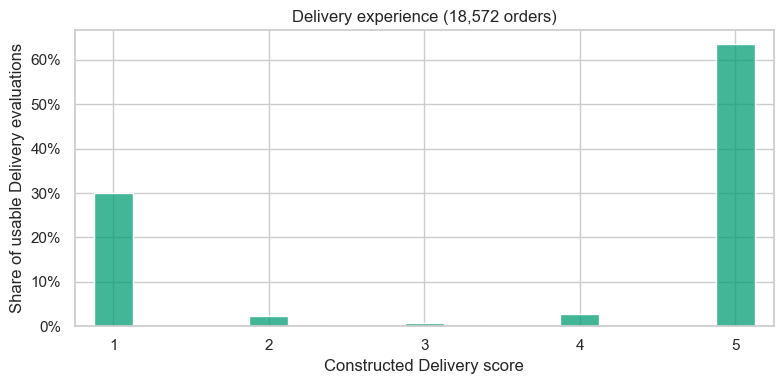

In [53]:
fig, ax = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=delivery_experience,
    x='delivery_score',
    bins=EXPERIENCE_SCORE_BINS,
    stat='percent',
    color=PALETTE[2],
    ax=ax,
)

ax.set(
    xlabel='Constructed Delivery score',
    ylabel='Share of usable Delivery evaluations',
    title=f'Delivery experience ({len(delivery_experience):,} orders)',
    xticks=[1, 2, 3, 4, 5],
    xlim=(0.75, 5.25),
)
ax.yaxis.set_major_formatter(PercentFormatter(100))

fig.tight_layout()
plt.show()


#### Compare On-Time and Late Delivery Experience


Compare Delivery scores between orders that were eventually delivered on time and those delivered late, separating evaluations submitted before delivery from those submitted on or after delivery.

Review timing affects how this comparison should be interpreted. Pre-delivery evaluations can reflect the delivery experience observed at the time of submission, including delivery timing or non-receipt, whereas evaluations submitted on or after delivery can also reflect the completed delivery outcome.

,delivery_outcome,review_timing,reviewed_orders,mean_delivery_score,low_score_share
0,Late,Before delivery,2429,1.13,0.96
1,Late,On/after delivery,410,2.24,0.70
2,On time,Before delivery,16,3.59,0.38
3,On time,On/after delivery,14749,4.29,0.17


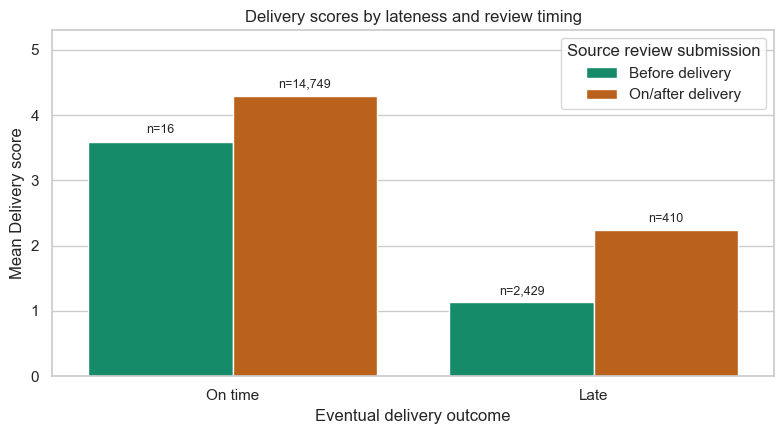

In [54]:
delivery_timing_experience = (
    delivery_experience
    .loc[delivery_experience.date_valid]
    .copy()
)

delivery_timing_experience['delivery_outcome'] = np.where(
    delivery_timing_experience.late_delivery,
    'Late',
    'On time',
)

delivery_timing_experience['review_timing'] = np.where(
    delivery_timing_experience.delivery_review_before_delivery,
    'Before delivery',
    'On/after delivery',
)

delivery_timing_summary = (
    delivery_timing_experience
    .groupby(
        [
            'delivery_outcome',
            'review_timing',
        ]
    )
    .agg(
        reviewed_orders=('order_id', 'size'),
        mean_delivery_score=('delivery_score', 'mean'),
        low_score_share=(
            'delivery_score',
            lambda s: s.lt(3).mean(),
        ),
    )
    .reset_index()
)

assert delivery_timing_summary.reviewed_orders.sum() == len(
    delivery_timing_experience
)


display(delivery_timing_summary)

fig, ax = plt.subplots(figsize=(8, 4.5))

sns.barplot(
    data=delivery_timing_summary,
    x='delivery_outcome',
    y='mean_delivery_score',
    hue='review_timing',
    order=['On time', 'Late'],
    hue_order=['Before delivery', 'On/after delivery'],
    palette=PALETTE[2:4],
    errorbar=None,
    ax=ax,
)

for container, timing in zip(
    ax.containers,
    ['Before delivery', 'On/after delivery'],
):
    timing_counts = (
        delivery_timing_summary
        .loc[
            delivery_timing_summary.review_timing.eq(timing)
        ]
        .set_index('delivery_outcome')
        .reindex(['On time', 'Late'])
        .reviewed_orders
    )

    ax.bar_label(
        container,
        labels=[
            f'n={int(count):,}' if pd.notna(count) else ''
            for count in timing_counts
        ],
        padding=4,
        fontsize=9,
    )

ax.set(
    xlabel='Eventual delivery outcome',
    ylabel='Mean Delivery score',
    title='Delivery scores by lateness and review timing',
    ylim=(0, 5.3),
)

ax.legend(title='Source review submission')

fig.tight_layout()
plt.show()

save_figure(fig, 'delivery_score_by_lateness_and_review_timing')

#### Relate Positive Lateness to Post-Delivery Evaluations

Restrict the comparison to late orders with valid delivery dates whose selected Delivery evaluation was submitted on or after recorded delivery. Group positive `days_late` into the existing severity ranges and show the reviewed-order count for each group.This restricted comparison excludes reviews submitted while the eventual delay was still unfolding.

,lateness_band,reviewed_orders,median_days_late,mean_delivery_score,low_score_share
0,1–2 days,240,1.00,2.30,0.68
1,3–7 days,141,4.00,2.26,0.70
2,8+ days,29,13.00,1.59,0.86


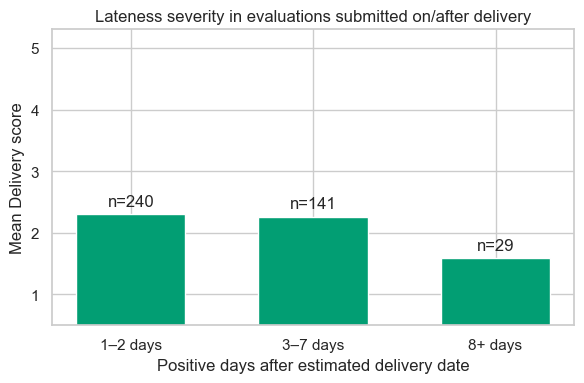

In [55]:
late_delivery_experience = (
    delivery_timing_experience
    .loc[
        delivery_timing_experience.late_delivery
        & delivery_timing_experience.delivery_review_before_delivery.eq(
            False
        )
    ]
    .copy()
)

assert late_delivery_experience.days_late.gt(0).all()
late_delivery_experience['lateness_band'] = pd.cut(
    late_delivery_experience.days_late,
    bins=[0, 2, 7, np.inf],
    labels=['1–2 days', '3–7 days', '8+ days'],
)

late_experience_summary = (
    late_delivery_experience
    .groupby('lateness_band', observed=True)
    .agg(
        reviewed_orders=('order_id', 'nunique'),
        median_days_late=('days_late', 'median'),
        mean_delivery_score=('delivery_score', 'mean'),
        low_score_share=('delivery_score', lambda s: s.lt(3).mean()),
    )
    .reset_index()
)

assert late_experience_summary.reviewed_orders.sum() == len(
    late_delivery_experience
)
display(late_experience_summary)

x = np.arange(len(late_experience_summary)) * 0.5

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    x,
    late_experience_summary['mean_delivery_score'],
    width=0.3,
    color=PALETTE[2],
)

ax.set_xticks(
    x,
    late_experience_summary['lateness_band'],
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f'n={count:,}'
        for count in late_experience_summary.reviewed_orders
    ],
    padding=4,
)

ax.set(
    xlabel='Positive days after estimated delivery date',
    ylabel='Mean Delivery score',
    title='Lateness severity in evaluations submitted on/after delivery',
    ylim=(0.5, 5.3),
)

ax.margins(x=0.05)

fig.tight_layout()
plt.show()

save_figure(fig, 'delivery_score_by_lateness_severity')

#### Compare Delivery Experience by Seller–Customer Distance

Use orders with an available seller–customer distance and retain the existing distance groups defined earlier in the notebook. For this comparison, include only evaluations submitted on or after delivery and distinguish on-time from late orders.

This separates differences associated with delivery distance from differences caused simply by a changing proportion of late orders. Labels show the number of reviewed orders in each group; the existing distance groups are reused without recalculating their boundaries.

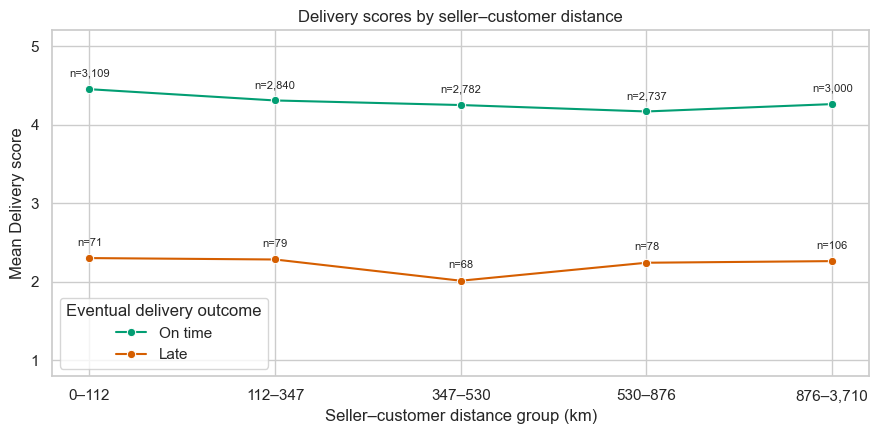

In [56]:
distance_delivery_experience = (
    delivery_timing_experience
    .loc[
        delivery_timing_experience.distance_km.notna()
        & delivery_timing_experience.delivery_review_before_delivery.eq(
            False
        )
    ]
    .copy()
)

distance_experience_summary = (
    distance_delivery_experience
    .groupby(
        [
            'distance_group',
            'delivery_outcome',
        ],
        observed=True,
    )
    .agg(
        reviewed_orders=('order_id', 'nunique'),
        mean_delivery_score=('delivery_score', 'mean'),
        low_score_share=(
            'delivery_score',
            lambda s: s.lt(3).mean(),
        ),
    )
    .reset_index()
)

assert distance_experience_summary.reviewed_orders.sum() == len(
    distance_delivery_experience
)

distance_experience_summary['distance_group_index'] = (
    distance_experience_summary.distance_group.cat.codes + 1
)

distance_groups = distance_delivery.distance_group.cat.categories

distance_group_labels = [
    f'{max(0, group.left):,.0f}–{group.right:,.0f}'
    for group in distance_groups
]

fig, ax = plt.subplots(figsize=(9, 4.5))

sns.lineplot(
    data=distance_experience_summary,
    x='distance_group_index',
    y='mean_delivery_score',
    hue='delivery_outcome',
    hue_order=['On time', 'Late'],
    palette=PALETTE[2:4],
    marker='o',
    errorbar=None,
    ax=ax,
)

for row in distance_experience_summary.itertuples(index=False):
    ax.annotate(
        f'n={row.reviewed_orders:,}',
        xy=(
            row.distance_group_index,
            row.mean_delivery_score,
        ),
        xytext=(0, 9),
        textcoords='offset points',
        ha='center',
        fontsize=8,
    )

ax.set_xticks(
    np.arange(1, len(distance_groups) + 1),
    distance_group_labels,
)

ax.set(
    xlabel='Seller–customer distance group (km)',
    ylabel='Mean Delivery score',
    title='Delivery scores by seller–customer distance',
    ylim=(0.8, 5.2),
    yticks=[1, 2, 3, 4, 5],
)

ax.legend(title='Eventual delivery outcome')

fig.tight_layout()
plt.show()

**Observation**

Delivery evaluations are highly polarized, with most scores concentrated at 1 or 5. Among evaluations submitted on or after delivery, on-time orders receive substantially higher mean Delivery scores than late orders. The corresponding pre-delivery comparison is much less informative because only 16 eventually on-time orders were evaluated before delivery. Review timing also matters, since evaluations are submitted before delivery and may reflect ongoing delay or non-receipt rather than the completed delivery outcome.

Among the 410 late orders evaluated on/after delivery, mean scores are similar for delays of 1–2 and 3–7 days (2.30 and 2.26), while the 8+ day group is lower (1.59) but contains only 29 orders. Across seller–customer distance groups, on-time orders consistently receive substantially higher scores than late orders, while neither group shows a clear monotonic change with distance. 

### 5. Overall Experience

**Examine the original customer rating across the full review population and relate it to the Product, Seller, and Delivery evaluations extracted from the same reviews.**

#### Examine the Overall Rating Distribution

Use every review record in the review table. The original review_score is the Overall Experience measure, and the grain remains one review record. Multiple reviews associated with the same order remain separate.

Begin by examining the distribution of the original customer ratings across this full population.

99,224 review records from 98,673 orders.


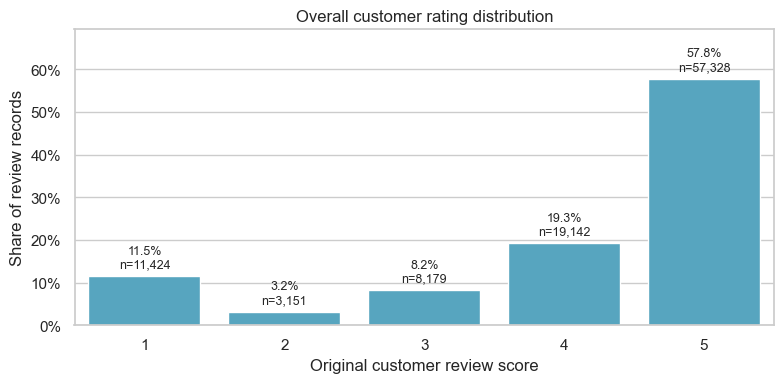

In [57]:
overall_experience = review_df[
    [
        'review_id',
        'order_id',
        'review_score',
        'review_comment_message',
    ]
].copy()

assert not overall_experience.duplicated(
    ['review_id', 'order_id']
).any()
assert overall_experience.review_score.isin([1, 2, 3, 4, 5]).all()


# Overall-rating distribution across the full review population.
overall_review_distribution = (
    overall_experience.review_score
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .rename('reviews')
    .rename_axis('review_score')
    .to_frame()
)

overall_review_distribution['share'] = (
    overall_review_distribution.reviews
    / len(overall_experience)
)

print(
    f'{len(overall_experience):,} review records from '
    f'{overall_experience.order_id.nunique():,} orders.'
)

fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(
    data=overall_review_distribution.reset_index(),
    x='review_score',
    y='share',
    color="#46AED0",
    errorbar=None,
    ax=ax,
)

ax.bar_label(
    ax.containers[0],
    labels=[
        f'{row.share:.1%}\nn={row.reviews:,}'
        for row in overall_review_distribution.itertuples()
    ],
    padding=4,
    fontsize=9,
)

ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set(
    xlabel='Original customer review score',
    ylabel='Share of review records',
    title='Overall customer rating distribution',
    ylim=(0, overall_review_distribution.share.max() * 1.2),
)

fig.tight_layout()
plt.show()

#### Compare Constructed Scores with the Original Rating

Attach the constructed Product, Seller, and Delivery scores to the original review records through the Portuguese review text. Do not apply the latest-per-order selection, entity-attribution rules, or dimension-specific eligibility filters used in the preceding analyses; the purpose here is to examine what customers evaluated within each review.

Among reviews that contain a Product, Seller, or Delivery evaluation, compare the constructed score for that dimension with the original customer rating from the same review. 

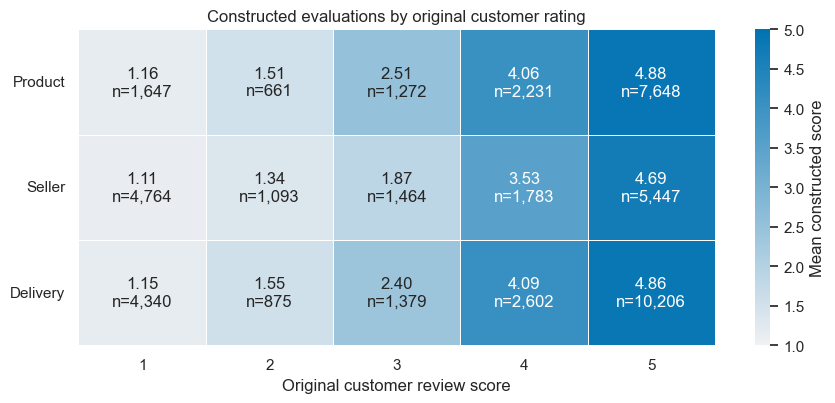

In [58]:
overall_experience = overall_experience.merge(
    dimension_score_lookup,
    left_on='review_comment_message',
    right_index=True,
    how='left',
    validate='m:1',
)

overall_dimension_long = (
    overall_experience
    .melt(
        id_vars=[
            'review_id',
            'order_id',
            'review_score',
        ],
        value_vars=score_columns,
        var_name='dimension',
        value_name='dimension_score',
    )
)

overall_dimension_long['dimension'] = (
    overall_dimension_long.dimension
    .str.removesuffix('_score')
)

overall_dimension_long['has_dimension_evaluation'] = (
    overall_dimension_long.dimension_score.notna()
)


overall_score_summary = (
    overall_dimension_long
    .dropna(subset=['dimension_score'])
    .groupby(
        [
            'dimension',
            'review_score',
        ]
    )
    .agg(
        evaluated_reviews=('review_id', 'size'),
        mean_dimension_score=('dimension_score', 'mean'),
    )
)

overall_mean_matrix = (
    overall_score_summary.mean_dimension_score
    .unstack('review_score')
    .reindex(
        index=DIMENSIONS,
        columns=[1, 2, 3, 4, 5],
    )
)

overall_count_matrix = (
    overall_score_summary.evaluated_reviews
    .unstack('review_score')
    .reindex(
        index=DIMENSIONS,
        columns=[1, 2, 3, 4, 5],
    )
)

overall_annotations = pd.DataFrame(
    '',
    index=overall_mean_matrix.index,
    columns=overall_mean_matrix.columns,
)

for dimension in DIMENSIONS:
    for rating in overall_mean_matrix.columns:
        mean_score = overall_mean_matrix.loc[dimension, rating]
        count = overall_count_matrix.loc[dimension, rating]

        if pd.notna(mean_score):
            overall_annotations.loc[dimension, rating] = (
                f'{mean_score:.2f}\n'
                f'n={int(count):,}'
            )

fig, ax = plt.subplots(figsize=(9, 4.2))

sns.heatmap(
    overall_mean_matrix,
    annot=overall_annotations,
    fmt='',
    cmap=sns.light_palette(PALETTE[0], as_cmap=True),
    vmin=1,
    vmax=5,
    linewidths=0.7,
    cbar_kws={'label': 'Mean constructed score'},
    yticklabels=[
        dimension.title()
        for dimension in DIMENSIONS
    ],
    ax=ax,
)

ax.set(
    xlabel='Original customer review score',
    ylabel='',
    title='Constructed evaluations by original customer rating',
)

ax.tick_params(axis='y', rotation=0)

fig.tight_layout()
plt.show()

save_figure(fig, 'dimension_score_vs_original_rating')

Next, return to the full review population. For each original customer rating, compare the share of reviews containing a constructed Product, Seller, or Delivery evaluation. This shows whether customers tend to evaluate particular dimensions more frequently at different levels of overall satisfaction.

In [59]:
overall_dimension_summary = (
    overall_dimension_long
    .groupby(
        [
            'review_score',
            'dimension',
        ]
    )
    .agg(
        reviews=('review_id', 'size'),
        evaluated_reviews=('has_dimension_evaluation', 'sum'),
    )
    .reset_index()
)

overall_dimension_summary['evaluation_share'] = (
    overall_dimension_summary.evaluated_reviews
    / overall_dimension_summary.reviews
)

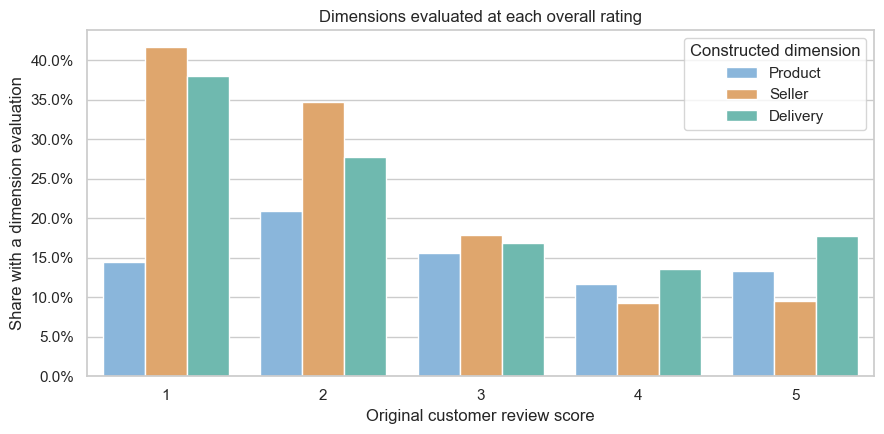

In [60]:
fig, ax = plt.subplots(figsize=(9, 4.5))

dimension_palette = {
    'product': '#7DB7E8',   # light blue
    'seller': '#F2A65A',    # soft orange
    'delivery': '#63C5B8',  # soft teal
}

sns.barplot(
    data=overall_dimension_summary,
    x='review_score',
    y='evaluation_share',
    hue='dimension',
    hue_order=DIMENSIONS,
    palette=dimension_palette,
    errorbar=None,
    ax=ax,
)

ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set(
    xlabel='Original customer review score',
    ylabel='Share with a dimension evaluation',
    title='Dimensions evaluated at each overall rating',
)

ax.legend(
    title='Constructed dimension',
    labels=[dimension.title() for dimension in DIMENSIONS],
)

fig.tight_layout()
plt.show()

save_figure(fig, 'dimension_evaluation_share_by_original_rating')

**Observation**

Within reviews that contain a constructed dimension evaluation, Product, Seller, and Delivery scores all rise closely with the original customer rating. 

The dimensions customers evaluate are not equally represented across overall ratings. Seller and Delivery evaluations are especially common among 1-star reviews, compared with Product. Their shares fall substantially at higher ratings, while Product evaluations vary less sharply. Delivery evaluations are also relatively common among 5-star reviews. These patterns show that the content of reviews differs across levels of overall satisfaction, so the constructed-score populations are selective subsets of the full rating population.

## **Business Performance vs Customer Experience**

Business Performance and Customer Experience have so far been examined separately. This section relates completed category merchandise value to Product experience and completed seller order volume to Seller experience. Merchandise value continues to exclude freight, and the established experience populations and reviewed-order thresholds are retained.

### 1. Completed Merchandise Value vs Product Experience

**Compare completed category merchandise value with Product experience, keeping reviewed-order counts visible.**

#### Prepare the Category Comparison

Join the completed commercial summary to the Product-experience summary one-to-one on category. Keep all categories in the joined table, then use the existing comparison population: named categories with at least 30 Product-reviewed orders. Product evaluations retain the established attribution and receipt-before-evaluation rules.

In [61]:
category_business_experience = (
    category_performance[
        ['orders', 'merchandise_value']
    ]
    .join(
        category_experience[
            [
                'product_review_orders',
                'mean_product_score',
                'low_product_score_share',
            ]
        ],
        how='left',
        validate='1:1',
    )
)

assert category_business_experience.product_review_orders.notna().all()

category_business_comparison = (
    category_business_experience
    .loc[categories_for_comparison.index]
    .copy()
)

category_comparison_value_share = (
    category_business_comparison.merchandise_value.sum()
    / category_performance.merchandise_value.sum()
)

print(
    f'{len(category_business_comparison):,} named categories meet the '
    f'{MIN_CATEGORY_REVIEW_ORDERS}-reviewed-order rule; '
    f'{category_business_comparison.product_review_orders.sum():,} '
    f'Product-reviewed orders are represented.'
)
print(
    f'These categories account for '
    f'{category_comparison_value_share:.1%} '
    f'of completed merchandise value.'
)


38 named categories meet the 30-reviewed-order rule; 12,278 Product-reviewed orders are represented.
These categories account for 93.0% of completed merchandise value.


#### Relate Commercial Scale to Product Experience

Plot completed merchandise value on a logarithmic scale against the mean
Product score. Marker size represents Product-reviewed orders. Label the
three largest categories by merchandise value and highlight
Computers/Accessories with its mean Product score and reviewed-order count.
Completed orders provide complementary volume information in the table below.

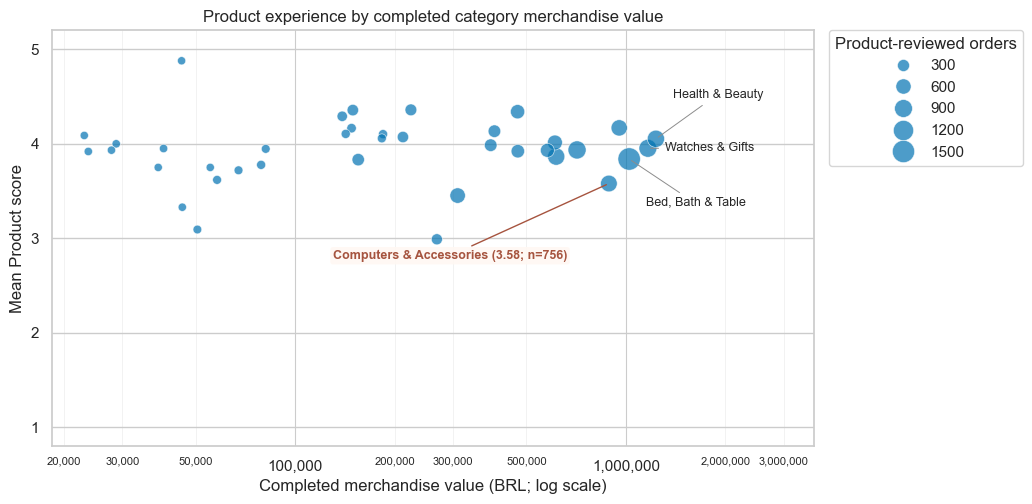

In [62]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))

sns.scatterplot(
    data=category_business_comparison.sort_values(
        'product_review_orders',
        ascending=False,
    ),
    x='merchandise_value',
    y='mean_product_score',
    size='product_review_orders',
    sizes=(35, 260),
    color=PALETTE[0],
    alpha=0.7,
    edgecolor='white',
    linewidth=0.5,
    legend='brief',
    ax=ax,
)

category_label_offsets = [(12, 32), (12, 0), (12, -32)]
category_display_names = {
    'health_beauty': 'Health & Beauty',
    'watches_gifts': 'Watches & Gifts',
    'bed_bath_table': 'Bed, Bath & Table',
}

for (category, row), offset in zip(
    category_business_comparison.nlargest(
        3, 'merchandise_value'
    ).iterrows(),
    category_label_offsets,
):
    ax.annotate(
        category_display_names.get(
            category,
            category.replace('_', ' ').title(),
        ),
        xy=(row.merchandise_value, row.mean_product_score),
        xytext=offset,
        textcoords='offset points',
        fontsize=9,
        va='center',
        arrowprops={
            'arrowstyle': '-',
            'color': '0.55',
            'linewidth': 0.7,
        },
    )

computers_accessories = category_business_comparison.loc[
    'computers_accessories'
]
ax.annotate(
    f'Computers & Accessories '
    f'({computers_accessories.mean_product_score:.2f}; '
    f'n={computers_accessories.product_review_orders:,.0f})',
    xy=(
        computers_accessories.merchandise_value,
        computers_accessories.mean_product_score,
    ),
    xytext=(-30, -52),
    textcoords='offset points',
    fontsize=9,
    fontweight='semibold',
    color='#A6543F',
    ha='right',
    va='center',
    bbox={
        'boxstyle': 'round,pad=0.2',
        'facecolor': '#FFF8F3',
        'edgecolor': 'none',
        'alpha': 0.9,
    },
    arrowprops={
        'arrowstyle': '-',
        'color': '#A6543F',
        'linewidth': 1.0,
    },
)

ax.set_xscale('log')

ax.xaxis.set_major_locator(
    LogLocator(base=10)
)
ax.xaxis.set_minor_locator(
    LogLocator(
        base=10,
        subs=(2, 3, 5),
    )
)

log_tick_formatter = FuncFormatter(
    lambda value, _: f'{value:,.0f}'
)

ax.xaxis.set_major_formatter(log_tick_formatter)
ax.xaxis.set_minor_formatter(log_tick_formatter)

ax.tick_params(
    axis='x',
    which='minor',
    labelsize=8,
)

ax.grid(
    axis='x',
    which='major',
    linewidth=0.8,
)
ax.grid(
    axis='x',
    which='minor',
    linewidth=0.5,
    alpha=0.35,
)

ax.set(
    xlabel='Completed merchandise value (BRL; log scale)',
    ylabel='Mean Product score',
    title='Product experience by completed category merchandise value',
    xlim=(
        category_business_comparison.merchandise_value.min() * 0.8,
        category_business_comparison.merchandise_value.max() * 3,
    ),
    ylim=(0.8, 5.2),
    yticks=[1, 2, 3, 4, 5],
)

ax.legend(
    title='Product-reviewed orders',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
)

fig.tight_layout()
plt.show()

save_figure(fig, 'category_value_vs_product_experience')

Inspect the ten comparison categories with the greatest completed
merchandise value. Show completed orders alongside Product-reviewed orders
and the existing share of Product scores below 3.

In [63]:
display(
    category_business_comparison
    .nlargest(10, 'merchandise_value')
    .assign(
        low_product_score_share=lambda d: (
            d.low_product_score_share.map('{:.1%}'.format)
        )
    )
)


,orders,merchandise_value,product_review_orders,mean_product_score,low_product_score_share
category,,,,,
health_beauty,8647,"1,233,131.72",823,4.05,22.8%
watches_gifts,5495,"1,166,176.98",902,3.95,25.1%
bed_bath_table,9272,"1,023,434.76",1534,3.84,28.2%
sports_leisure,7530,"954,852.55",712,4.17,19.8%
computers_accessories,6530,"888,724.61",756,3.58,34.8%
furniture_decor,6307,"711,927.69",929,3.94,25.7%
housewares,5743,"615,628.69",823,3.86,27.3%
cool_stuff,3559,"610,204.10",566,4.01,24.2%
auto,3810,"578,966.65",469,3.93,26.4%


**Observation**

Product scores do not rise consistently with completed category merchandise value. Among the ten largest comparison categories, computers/accessories has the lowest mean Product score (3.58), with 34.8% of scores below 3, while sports/leisure has the highest mean (4.17), with 19.8% below 3. Commercial importance therefore coexists with differing Product evaluations within the eligible reviewed-order population.

### 2. Completed Order Volume vs Seller Experience

**Compare completed seller order volume with Seller evaluations, preserving the distinction between completed commerce and all-status experience.**


#### Prepare the Seller Comparison

Join `seller_performance` to `seller_experience_summary`. Start from sellers with completed commercial activity and retain their existing Seller evaluations, including evaluations from non-delivered orders.

Apply the established minimum of 10 Seller-reviewed orders. Sellers with evaluations but no completed activity remain outside this comparison.Missing review counts become zero; missing experience measures remainmissing.

In [64]:
seller_business_experience = (
    seller_performance[
        ['orders', 'merchandise_value']
    ]
    .join(
        seller_experience_summary[
            [
                'seller_review_orders',
                'mean_seller_score',
                'non_delivered_review_share',
            ]
        ],
        how='left',
        validate='1:1',
    )
)

seller_business_experience['seller_review_orders'] = (
    seller_business_experience.seller_review_orders
    .fillna(0)
    .astype(int)
)

seller_business_comparison = (
    seller_business_experience
    .loc[
        seller_business_experience.seller_review_orders.ge(
            MIN_SELLER_REVIEW_ORDERS
        )
    ]
    .copy()
)

expected_seller_comparison_ids = seller_performance.index.intersection(
    seller_experience_comparison.index,
    sort=False,
)
assert seller_business_comparison.index.equals(
    expected_seller_comparison_ids
)

sellers_without_completed_activity = (
    seller_experience_summary.index.difference(seller_performance.index)
)

print(
    f'{len(seller_business_comparison):,} active sellers meet the '
    f'{MIN_SELLER_REVIEW_ORDERS}-reviewed-order rule; '
    f'{seller_business_comparison.seller_review_orders.sum():,} '
    f'Seller-reviewed orders are represented across all statuses.'
)
print(
    f'{len(sellers_without_completed_activity):,} evaluated sellers '
    f'have no completed activity and are outside this comparison.'
)


317 active sellers meet the 10-reviewed-order rule; 9,539 Seller-reviewed orders are represented across all statuses.
40 evaluated sellers have no completed activity and are outside this comparison.


#### Relate Commercial Scale to Seller Experience

Plot completed orders on a logarithmic scale against the mean Seller score.
Marker size shows Seller-reviewed orders, and labels identify the three
largest sellers by completed-order volume using shortened seller IDs.
Commercial order counts and all-status reviewed-order counts describe
different populations and are not used to calculate a review-coverage rate.

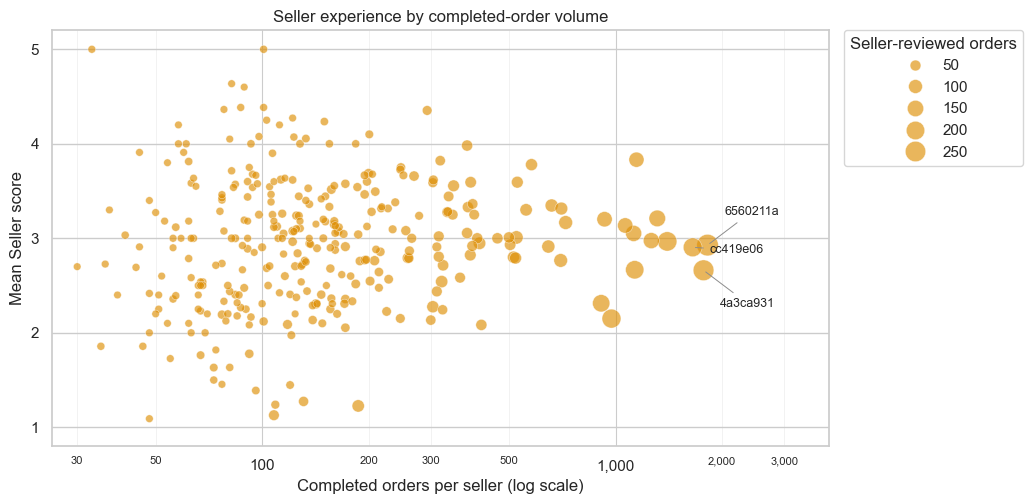

In [65]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))

sns.scatterplot(
    data=seller_business_comparison.sort_values(
        'seller_review_orders',
        ascending=False,
    ),
    x='orders',
    y='mean_seller_score',
    size='seller_review_orders',
    sizes=(30, 240),
    color=PALETTE[1],
    alpha=0.65,
    edgecolor='white',
    linewidth=0.4,
    legend='brief',
    ax=ax,
)

seller_label_offsets = [(12, 24), (12, -24), (12, -2)]

for (seller_id, row), offset in zip(
    seller_business_comparison.nlargest(3, 'orders').iterrows(),
    seller_label_offsets,
):
    ax.annotate(
        seller_id[:8],
        xy=(row.orders, row.mean_seller_score),
        xytext=offset,
        textcoords='offset points',
        fontsize=9,
        va='center',
        arrowprops={
            'arrowstyle': '-',
            'color': '0.55',
            'linewidth': 0.7,
        },
    )

ax.set_xscale('log')
ax.set_xscale('log')

ax.xaxis.set_major_locator(
    LogLocator(base=10)
)
ax.xaxis.set_minor_locator(
    LogLocator(
        base=10,
        subs=(2, 3, 5),
    )
)

log_tick_formatter = FuncFormatter(
    lambda value, _: f'{value:,.0f}'
)

ax.xaxis.set_major_formatter(log_tick_formatter)
ax.xaxis.set_minor_formatter(log_tick_formatter)

ax.tick_params(
    axis='x',
    which='minor',
    labelsize=8,
)

ax.grid(
    axis='x',
    which='major',
    linewidth=0.8,
)
ax.grid(
    axis='x',
    which='minor',
    linewidth=0.5,
    alpha=0.35,
)

ax.set(
    xlabel='Completed orders per seller (log scale)',
    ylabel='Mean Seller score',
    title='Seller experience by completed-order volume',
    xlim=(
        seller_business_comparison.orders.min() * 0.85,
        seller_business_comparison.orders.max() * 2.2,
    ),
    ylim=(0.8, 5.2),
    yticks=[1, 2, 3, 4, 5],
)

ax.legend(
    title='Seller-reviewed orders',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
)

fig.tight_layout()
plt.show()

save_figure(fig, 'seller_volume_vs_seller_experience')

**Observation**

Mean Seller score does not show a clear increase with completed-order volume. Sellers with tens to a few hundred completed orders span a wide range of evaluations, while the highest-volume sellers are more concentrated around the middle of the score scale. Thus, larger completed-order volume is not consistently associated with stronger Seller evaluations within the comparison population.

## Summary

The Business Performance analysis shows substantial concentration and growth:

- Customer demand is geographically concentrated, with São Paulo, Rio de Janeiro, and Minas Gerais accounting for roughly two thirds of completed orders in the state summary.
- Product and category importance differs depending on whether it is measured by item volume or merchandise value. The increase in merchandise value is primarily associated with higher item volume, with Watches/Gifts and Health/Beauty among the largest contributors.
- The largest 10% of active sellers by completed merchandise value account for about 68% of total completed value.
- Late-delivery rates increase with seller–customer distance, although substantial variation remains between sellers with similar distance-based benchmarks.

The Customer Experience analysis shows that the constructed dimensions capture distinct parts of the purchasing experience:

- Product evaluations are generally favorable but vary across categories, while Seller evaluations show substantially more low scores and considerable variation across sellers.
- Delivery evaluations are strongly polarized, and late deliveries receive markedly lower scores than on-time deliveries when evaluations are submitted on or after delivery; more severe delays are associated with particularly low evaluations.
- The constructed scores are closely associated with the original customer rating, while the dimensions customers evaluate are not equally represented across overall rating levels.

Finally, Business Performance and Customer Experience provide complementary rather than interchangeable views of marketplace performance:

- Categories with greater completed merchandise value do not systematically receive higher Product scores.
- Sellers with greater completed-order volume do not systematically receive higher Seller scores.